> **Archived original (in Hebrew).** This is the first version of the analysis, kept for reference with its original outputs. It follows the structure of the course assignment. The current, revised analysis is in the notebooks one folder up; see the main README for what changed. Data loading was updated to read the CSV files in `data/`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
import statsmodels.api as sm
import pickle as pkl
import statsmodels.formula.api as smf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from scipy.stats import poisson
from scipy.stats import chi2
from mpl_toolkits.mplot3d import Axes3D
import plotly.graph_objects as go

<div dir="rtl">

# פרויקט מסכם תשפ"ו סמסמטר א
    
### בפרויקט זה ננתח חברת כימיקלים. בחברה יש שני סוגים של כימיקלים  : Sulfuric_Acid ו - Hydrochloric_acid. 
    
### כל עובד מתמחה אך ורק בסוג אחד של כימיקל. לכן הוא לא יעבוד עם ההסוג השני בשום צורה ואינו מוסמך לכך.


### בפרויקט נרצה להתמקם בתאונות עבודה העלולות להתרחש במפעל.


### החברה ממוקמת בישראל ויש לה מפעלים המפוזרים ברחבי המדינה.
    
### בנוסף, כל עובד עובר מבחני בטיחות ומקבל עליהם ציון - מספר בין 1 ל 10. כאשר 10 הכי גבוה. 
        
## Dataset חלק א':
    
###  במפעל ישנם חומרים כימיים: 'Hydrochloric_acid' ו 'Sulfuric Acid'
    
###  לאחר  השימוש באחד החומרים נשאר שאריות של החומר וקשה להבחין איזה חומר זה בין השניים. 
    
### מה שכן אנחנו יודעים זה את הטמפרטורה של החומר והאם התגבשו גושים בחומר או לא. שתי תכונות אלו יכולות להעיד על סוג החומר. 
    
### בdataset יש את העמודות הבאות: 
    

### Intercept: A column of ones 
### temp: the chimical temperture 
### rigid_bool: Categorial  - true if there are some lumps. (האם יש גושים)
### Hydrochloric_acid: True if Hydrochloric acid, False if Sulfuric Acid

<div dir="rtl">

## חלק א:
    

    
### 1. נא לבנות מודל רגרסיה לוגיסטית שחוזה את ההסתברות שהחומר הוא Hydrochloric_acid.  יש להציג את המשוואה הסופית לתחזית.
    
### כעת נרצה לסווג האם חומר הוא  'Hydrochloric_acid' או 'Sulfuric Acid'
### לשם אחידות - נגדיר Hydrochloric_acid  הוא 1 ואילו Sulfuric Acid הוא 0
    
### 2. האם קיים ערך סף לסיווג כך שהsensativity וגם הspecaficity מעל 0.6? אם כן, מהו תחום ערכי הסף המקיימים זאת?
    
### 3.   מהו הthreshold שממקסם את הaccuracy? אם יש יותר מאחד נא לפרט את התחום
    
### מה ההסתברות שהחומר הוא Hydrochloric_acid בשלושת המקרים הבאים: 
    
### א. טמפרטורה 23.2 ונשאר שאריות
    
### ב. טמפרטורה 24.2 ונשאר שאריות
    
### ג. טמפרטורה 25.2 ונשאר שאריות
    
### 4.  מהו הlog odd ratio בין ב' לא' ובין ג' לב' ובין ג' לא'? 
    
### האם שלוש הערכים שקיבלתם שווים? האם חלקם שווים? נא הסבר.י את משמעות התוצאה שקיבלתם.

In [2]:
df_part_1 = pd.read_csv('../../data/acid_classification.csv').rename(columns={'lumps': 'rigid_bool', 'hydrochloric_acid': 'Hydrochloric_acid'})
df_part_1[['rigid_bool', 'Hydrochloric_acid']] = df_part_1[['rigid_bool', 'Hydrochloric_acid']].astype(bool)
df_part_1.insert(0, 'Intercept', 1.0)
df_part_1.head()

,Intercept,temp,rigid_bool,Hydrochloric_acid
0,1.0,20.027506,False,True
1,1.0,28.172875,False,False
2,1.0,38.070620,False,False
3,1.0,46.826767,True,False
4,1.0,38.528257,False,True


In [3]:
df_part_1.dtypes

Intercept            float64
temp                 float64
rigid_bool              bool
Hydrochloric_acid       bool
dtype: object

In [4]:
df_part_1.isna().sum()

Intercept            0
temp                 0
rigid_bool           0
Hydrochloric_acid    0
dtype: int64

In [5]:
df_part_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Intercept          120 non-null    float64
 1   temp               120 non-null    float64
 2   rigid_bool         120 non-null    bool   
 3   Hydrochloric_acid  120 non-null    bool   
dtypes: bool(2), float64(2)
memory usage: 2.2 KB


In [6]:
df_part_1.describe()

,Intercept,temp
count,120.0,120.000000
mean,1.0,31.241173
std,0.0,11.341697
min,1.0,10.285385
25%,1.0,22.832700
50%,1.0,30.532572
75%,1.0,40.825588
max,1.0,49.697072


In [7]:
df_part_1.duplicated().sum()

0

In [8]:
df_part_1['rigid_bool'].unique()

array([False,  True])

In [9]:
df_part_1['rigid_bool'] = df_part_1['rigid_bool'].astype(int)

<Axes: xlabel='rigid_bool', ylabel='count'>

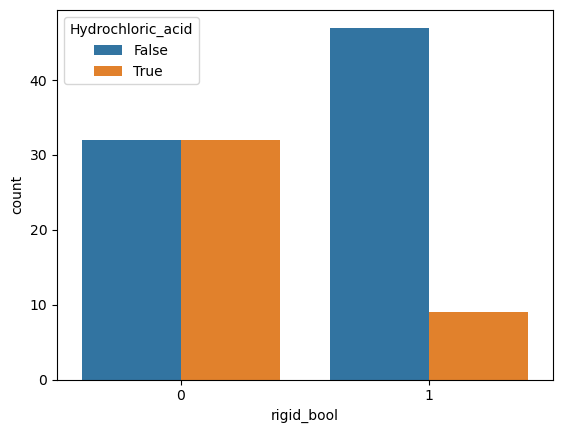

In [10]:
sns.countplot(x='rigid_bool', hue='Hydrochloric_acid', data=df_part_1)

<Axes: xlabel='Hydrochloric_acid', ylabel='temp'>

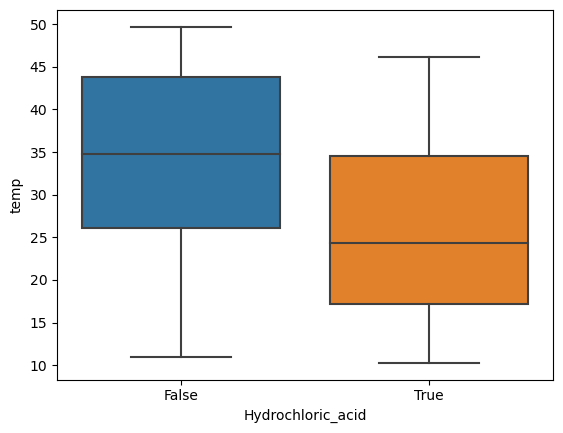

In [11]:
sns.boxplot(x='Hydrochloric_acid', y='temp', data=df_part_1)

### בדיקה גרפית של המשתנים

על מנת להבין טוב יותר את הנתונים בוצעה בדיקה גרפית של הקשרים בין המשתנים.

בגרף הראשון מוצגת ההתפלגות של המשתנה `rigid_bool` לפי סוג החומר (`Hydrochloric_acid`). ניתן לראות כי כאשר אין גושים בחומר (ערך 0), מספר המקרים של שני סוגי החומרים דומה יחסית. לעומת זאת, כאשר קיימים גושים (ערך 1), מרבית המקרים שייכים לחומר שאינו חומצה הידרוכלורית.

בגרף השני מוצגת התפלגות הטמפרטורה (`temp`) עבור כל אחד מסוגי החומרים (`Hydrochloric_acid`). ניתן לראות כי הטמפרטורות של חומצה הידרוכלורית נוטות להיות נמוכות יותר בממוצע בהשוואה לחומר השני.

בדיקה גרפית ראשונית זו מסייעת להבין את הקשרים בין המשתנים ומרמזת כי המשתנים טמפרטורה (`temp`) וקיום גושים (`rigid_bool`) עשויים להיות משתנים חשובים במודל הסיווג.

# <span style="color:#1F4E79">מבוא</span>

בפרויקט זה נבחנת בעיית זיהוי של חומרים כימיים במפעל. לאחר שימוש בחומרים שונים בתהליך הייצור נשארות לעיתים שאריות חומר, ולעיתים קשה להבחין האם מדובר בחומצה הידרוכלורית או בחומצה גופרתית.

לצורך הזיהוי נמדדות שתי תכונות של החומר: הטמפרטורה שלו, וכן האם קיימים בו גושים לאחר השימוש. תכונות אלו עשויות להעיד על סוג החומר ולכן ניתן להשתמש בהן לצורך סיווג החומר.

מטרת הניתוח היא לבנות מודל סטטיסטי אשר יעריך את ההסתברות שהחומר הוא חומצה הידרוכלורית, ולבחון את ביצועי הסיווג של המודל באמצעות מדדים שונים של איכות הסיווג. בנוסף נבחן כיצד שינוי בטמפרטורה משפיע על הסיכוי לסיווג החומר.

# <span style="color:#1F4E79">סעיף 1: בניית מודל רגרסיה לוגיסטית לחיזוי סוג החומר</span>

In [12]:
X = df_part_1[['temp','rigid_bool']]
y = df_part_1['Hydrochloric_acid']

X = sm.add_constant(X)

In [13]:
result = sm.Logit(y, X).fit()

print(result.summary())

Optimization terminated successfully.
         Current function value: 0.491851
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:      Hydrochloric_acid   No. Observations:                  120
Model:                          Logit   Df Residuals:                      117
Method:                           MLE   Df Model:                            2
Date:                Thu, 19 Mar 2026   Pseudo R-squ.:                  0.2340
Time:                        02:24:46   Log-Likelihood:                -59.022
converged:                       True   LL-Null:                       -77.056
Covariance Type:            nonrobust   LLR p-value:                 1.472e-08
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9488      0.804      3.668      0.000       1.373       4.525
temp          -0.0931      0.

In [14]:
result.params

const         2.948799
temp         -0.093051
rigid_bool   -2.069666
dtype: float64

# סיכום סעיף 1 - בניית מודל רגרסיה לוגיסטית

מטרת סעיף זה היא לבנות מודל רגרסיה לוגיסטית אשר חוזה את ההסתברות שהחומר הוא  
**Hydrochloric Acid**.

המשתנה המוסבר הוא:

**Hydrochloric_acid**

כאשר:

- 1 = Hydrochloric Acid  
- 0 = Sulfuric Acid

המשתנים המסבירים במודל הם:

- **temp** – טמפרטורת החומר  
- **rigid_bool** – משתנה בינארי המציין האם קיימים גושים בחומר

מאחר והמשתנה המוסבר הוא בינארי, נעשה שימוש במודל **רגרסיה לוגיסטית**.

המודל הלוגיסטי מתאר את הקשר בין המשתנים באמצעות פונקציית הלוגיט:

$$
\log\left(\frac{p}{1-p}\right)
=
\beta_0 + \beta_1 \cdot temp + \beta_2 \cdot rigid\_bool
$$

כאשר:

$$
p = P(Hydrochloric\_acid = 1)
$$

לאחר אמידת המודל התקבלו המקדמים הבאים:

- $\beta_0 = 2.9488$
- $\beta_1 = -0.0931$
- $\beta_2 = -2.0697$

ולכן משוואת הלוגיט של המודל היא:

$$
\log\left(\frac{p}{1-p}\right)
=
2.9488
-0.0931 \cdot temp
-2.0697 \cdot rigid\_bool
$$

מתוך משוואת הלוגיט ניתן לכתוב את פונקציית ההסתברות:

$$
P(Hydrochloric\_acid = 1)
=
\frac{1}{1 + e^{-(2.9488 - 0.0931 \cdot temp - 2.0697 \cdot rigid\_bool)}}
$$

משוואה זו מאפשרת לחשב עבור כל תצפית את ההסתברות שהחומר הוא  
**Hydrochloric Acid** על בסיס הטמפרטורה וקיום גושים בחומר.

# <span style="color:#1F4E79">סעיף 2: מציאת ערך סך לסיווג</span>

התחום הוא בין: 0.24 לבין 0.41


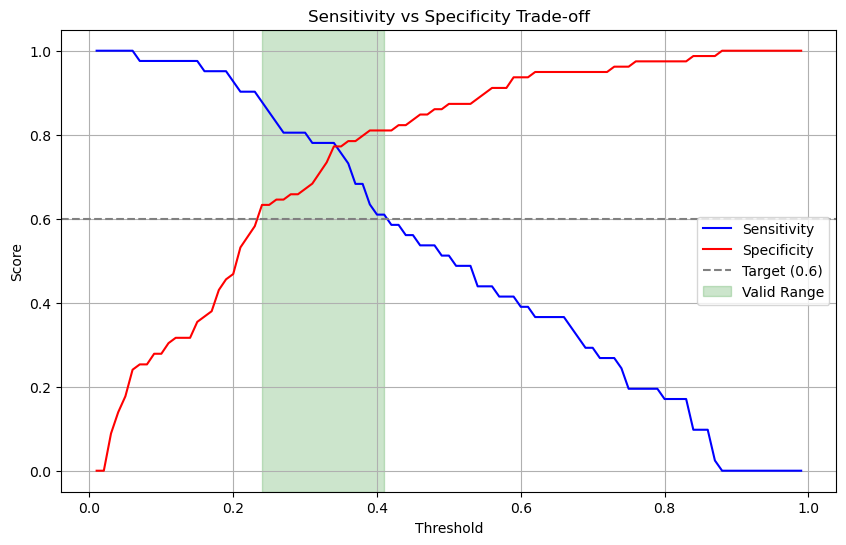

In [15]:
# 1. חישוב ההסתברויות החזויות לכל דוגמה בדאטה
y_prob = result.predict(X)

# 2. הכנת רשימות לשמירת התוצאות
thresholds = np.linspace(0.01, 0.99, 99) # בודקים כל מאית: 0.00, 0.01, ..., 1.00
valid_thresholds = [] # פה נשמור את הספים הטובים
sens_list = []
spec_list = []

# 3. לולאה שעוברת על כל סף ובודקת אותו
for t in thresholds:
    # סיווג לפי הסף הנוכחי: אם ההסתברות גדולה מ-t זה 1, אחרת 0
    y_pred = (y_prob >= t).astype(int)
    
    # חישוב TP, TN, FP, FN
    # TP: המודל אמר 1 ובמציאות 1
    TP = ((y_pred == 1) & (y == 1)).sum()
    # TN: המודל אמר 0 ובמציאות 0
    TN = ((y_pred == 0) & (y == 0)).sum()
    # FP: המודל אמר 1 אבל במציאות 0
    FP = ((y_pred == 1) & (y == 0)).sum()
    # FN: המודל אמר 0 אבל במציאות 1
    FN = ((y_pred == 0) & (y == 1)).sum()
    
    # חישוב המדדים (הוספנו הגנה מפני חילוק ב-0)
    sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    
    sens_list.append(sensitivity)
    spec_list.append(specificity)
    
    # הבדיקה: האם שניהם מעל 0.6?
    if sensitivity > 0.6 and specificity > 0.6:
        valid_thresholds.append(t)

# 4. הצגת התשובה הסופית
if valid_thresholds:
    min_t = min(valid_thresholds)
    max_t = max(valid_thresholds)
    print(f"התחום הוא בין: {min_t:.2f} לבין {max_t:.2f}")
else:
    print("לא נמצא שום ערך סף שבו גם הרגישות וגם הסגוליות מעל 0.6")

# 5. בונוס: גרף שמראה את התחום (מרשים מאוד בעבודות)
plt.figure(figsize=(10, 6))
plt.plot(thresholds, sens_list, label='Sensitivity', color='blue')
plt.plot(thresholds, spec_list, label='Specificity', color='red')
plt.axhline(0.6, color='gray', linestyle='--', label='Target (0.6)')
# צביעת האזור הטוב בירוק
if valid_thresholds:
    plt.axvspan(min_t, max_t, color='green', alpha=0.2, label='Valid Range')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Sensitivity vs Specificity Trade-off')
plt.legend()
plt.grid(True)
plt.show()

# יהיו מעל 0.6 Sensitivity-ו Specificity-סיכום סעיף 2: מציאת ערך סף כך ש 

מודל רגרסיה לוגיסטית מחזיר הסתברות לכך שהחומר הוא **Hydrochloric_acid**.

כדי לבצע סיווג בינארי יש לבחור ערך סף (Threshold) כך ש:

- אם  

$$
P(Y=1|X) \ge t
$$

נחזיר:

$$
\hat{Y}=1
$$

כלומר החומר מסווג כ־Hydrochloric_acid.

- אחרת:

$$
\hat{Y}=0
$$

כלומר Sulfuric Acid.

---

### מדדי ביצוע

נבדקו שני מדדים מרכזיים:

**Sensitivity זוהו באופן נכון מכל המקרים בהם החומר היה הידרוכולי אסיד**

$$
Sensitivity = \frac{TP}{TP + FN}
$$

מודד את היכולת לזהות נכון Hydrochloric_acid.

---

**Specificity מתוך כל אלו שזהו כחומר גופרית, כמה מהם באמת מחומר גופרית**

$$
Specificity = \frac{TN}{TN + FP}
$$

מודד את היכולת לזהות נכון Sulfuric Acid.

---

### שיטת הבדיקה

נבדקו ערכי סף בטווח:

$$
0.01 \le t \le 0.99
$$

בקפיצות של 0.01.

עבור כל סף חושבו:

- Sensitivity  
- Specificity  

ונבדק האם מתקיים:

$$
Sensitivity > 0.6
$$

וגם

$$
Specificity > 0.6
$$

---

### תוצאות

נמצא כי קיים תחום ערכי סף המקיים את הדרישה.

התחום הוא:

$$
0.24 \le t \le 0.41
$$

כלומר כל ערך סף בטווח זה מאפשר סיווג שבו גם הרגישות וגם הסגוליות גבוהות מ־0.6.

---

### המחשה גרפית

בגרף ניתן לראות את הקשר בין ערך הסף לבין Sensitivity ו־Specificity.

האזור המסומן בירוק מציין את תחום ערכי הסף שבו שני המדדים נמצאים מעל 0.6.

# <span style="color:#1F4E79"> סעיף 3: מציאת ערך הסף שממקסם את הדיוק וחישוב הסבתרויות למקרים נתונים </span>

In [16]:
# חישוב ההסתברויות החזויות
y_prob = result.predict(X)

# בדיקת Accuracy עבור ערכי סף שונים
thresholds = np.linspace(0.01, 0.99, 99)

best_accuracy = 0
best_thresholds = []

for t in thresholds:
    
    # סיווג לפי הסף
    y_pred = (y_prob >= t).astype(int)
    
    # חישוב Accuracy
    accuracy = (y_pred == y).mean()
    
    # בדיקה האם זה הדיוק הגבוה ביותר
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_thresholds = [t]
        
    elif accuracy == best_accuracy:
        best_thresholds.append(t)

# מציאת הטווח
min_best_t = min(best_thresholds)
max_best_t = max(best_thresholds)

print("Max Accuracy:", best_accuracy)

if min_best_t == max_best_t:
    print("Best Threshold:", round(min_best_t,2))
else:
    print("Best Threshold Range:", round(min_best_t,2), "to", round(max_best_t,2))

Max Accuracy: 0.775
Best Threshold: 0.34


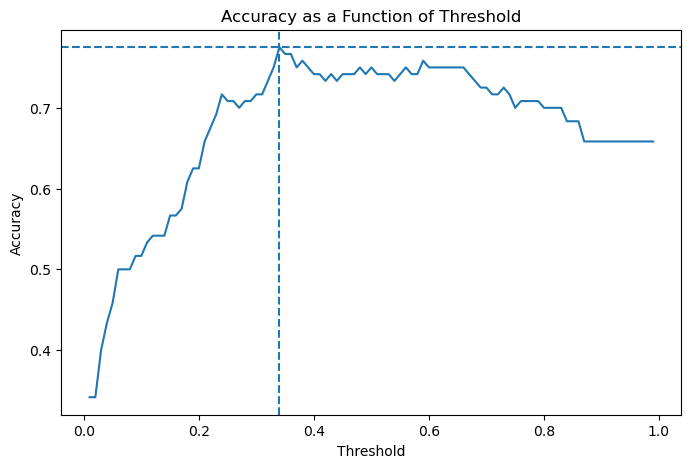

In [17]:
accuracies = []

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)
    acc = (y_pred == y).mean()
    accuracies.append(acc)

plt.figure(figsize=(8,5))
plt.plot(thresholds, accuracies)
plt.xlabel("Threshold")
plt.ylabel("Accuracy")
plt.title("Accuracy as a Function of Threshold")

# סימון הסף הכי טוב
plt.axvline(x=min_best_t, linestyle='--')
plt.axhline(y=best_accuracy, linestyle='--')

plt.show()

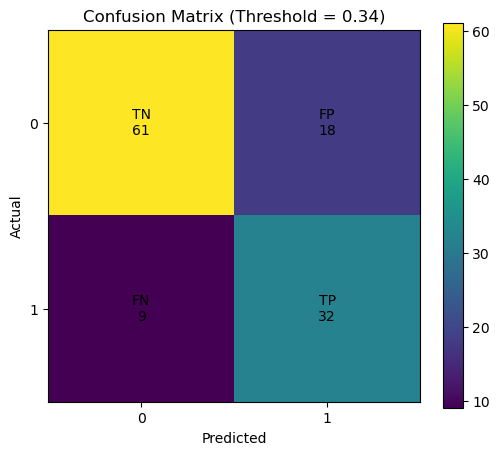

In [18]:
best_t = min_best_t
y_pred_best = (y_prob >= best_t).astype(int)

cm = confusion_matrix(y, y_pred_best)

# חילוץ הערכים
tn, fp, fn, tp = cm.ravel()

# יצירת טקסט לכל תא
labels = np.array([
    [f"TN\n{tn}", f"FP\n{fp}"],
    [f"FN\n{fn}", f"TP\n{tp}"]
])

plt.figure(figsize=(6,5))
plt.imshow(cm)
plt.title(f"Confusion Matrix (Threshold = {round(best_t,2)})")
plt.colorbar()

# תוויות צירים
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0,1], ["0", "1"])
plt.yticks([0,1], ["0", "1"])

# הוספת הטקסט בתוך התאים
for i in range(2):
    for j in range(2):
        plt.text(j, i, labels[i, j],
                 ha="center", va="center", color="black")

plt.show()

In [19]:
(61+32)/(61+32+9+18)

0.775

In [20]:
new_cases = pd.DataFrame({
    'Intercept': [1,1,1],
    'temp': [23.2, 24.2, 25.2],
    'rigid_bool': [1,1,1]
})

predictions = result.predict(new_cases)

predictions

0    0.217612
1    0.202186
2    0.187591
dtype: float64

# Accuracy סיכום סעיף 3: מציאת ערך הסף שממקסם את 

מודל רגרסיה לוגיסטית מחזיר הסתברות לכך שהחומר הוא **Hydrochloric_acid**. 
כדי לבצע סיווג בינארי יש לבחור ערך סף \(t\), כך שהסיווג מתבצע לפי הכלל הבא:

$$
\hat{Y} =
\begin{cases}
1 & \text{if } \hat{p} \ge t \\
0 & \text{if } \hat{p} < t
\end{cases}
$$

כאשר \(\hat{p}\) היא ההסתברות החזויה על ידי המודל.

לאחר הסיווג חושב מדד הדיוק (Accuracy):

$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

כדי למצוא את ערך הסף האופטימלי נבדקו ערכי סף בטווח:

$$
0.01 \le t \le 0.99
$$

בקפיצות של 0.01.  
עבור כל ערך סף חושב ה-Accuracy של הסיווג.

נמצא כי הדיוק המקסימלי שהמודל משיג הוא:

$$
Accuracy = 0.775
$$

וערך הסף שממקסם את הדיוק הוא:

$$
t = 0.34
$$

---

## חישוב הסתברות עבור מקרים נתונים

לאחר אמידת מודל הרגרסיה הלוגיסטית, ניתן לחשב עבור כל תצפית את ההסתברות שהחומר הוא **Hydrochloric_acid** באמצעות פונקציית החיזוי של המודל.


$$
\log\left(\frac{p}{1-p}\right)
=
2.9488
-0.0931 \cdot temp
-2.0697 \cdot rigid\_bool
$$


### א. טמפרטורה 23.2 ונשארו שאריות

$$
P(Hydrochloric\_acid = 1) = 0.2176
$$

כלומר הסתברות של כ־**21.76%** שהחומר הוא Hydrochloric_acid.

---

### ב. טמפרטורה 24.2 ונשארו שאריות

$$
P(Hydrochloric\_acid = 1) = 0.2022
$$

כלומר הסתברות של כ־**20.22%** שהחומר הוא Hydrochloric_acid.

---

### ג. טמפרטורה 25.2 ונשארו שאריות

$$
P(Hydrochloric\_acid = 1) = 0.1876
$$

כלומר הסתברות של כ־**18.76%** שהחומר הוא Hydrochloric_acid.

# <span style="color:#1F4E79"> Log Odds Ratio סעיף 4: חישוב והשוואה בין המקרים </span>

### הסתברויות מותנות

$$
\pi_1 = \frac{1}{1 + e^{b_0 + b_1 x_1 + b_2 \cdot (x_2+1)}}
$$

$$
\pi_2 = \frac{1}{1 + e^{b_0 + b_1 x_1 + b_2 \cdot x_2}}
$$

---

### יחס הסיכויים (Odds Ratio)

$$
\log\left(\frac{\pi_1 / (1 - \pi_1)}{\pi_2 / (1 - \pi_2)}\right)
=
\log\left(
\frac{e^{b_0 + b_1 x_1 + b_2 \cdot (x_2+1)}}{e^{b_0 + b_1 x_1+ b_2 \cdot x_2}}
\right)
=
\log(e^{b_2})
=
b_2
$$

In [21]:
# --- שלב 1: שליפת ההסתברויות מסעיף 3 ---
# סדר המקרים:
# A -> temp = 23.2
# B -> temp = 24.2
# C -> temp = 25.2

prob_A = predictions[0]
prob_B = predictions[1]
prob_C = predictions[2]


# --- שלב 2: חישוב Odds ---
odds_A = prob_A / (1 - prob_A)
odds_B = prob_B / (1 - prob_B)
odds_C = prob_C / (1 - prob_C)


# --- שלב 3: חישוב Log Odds ---
log_odds_A = np.log(odds_A)
log_odds_B = np.log(odds_B)
log_odds_C = np.log(odds_C)


# --- שלב 4: חישוב Log Odds Ratio ---
ratio_B_A = log_odds_B - log_odds_A
ratio_C_B = log_odds_C - log_odds_B
ratio_C_A = log_odds_C - log_odds_A


# --- שלב 5: מקדם הטמפרטורה מהמודל להשוואה ---
beta_temp = result.params['temp']


print("Log Odds Ratio B-A:", round(ratio_B_A,4))
print("Log Odds Ratio C-B:", round(ratio_C_B,4))
print("Log Odds Ratio C-A:", round(ratio_C_A,4))

print("\nTemperature coefficient from model:", round(beta_temp,4))

Log Odds Ratio B-A: -0.0931
Log Odds Ratio C-B: -0.0931
Log Odds Ratio C-A: -0.1861

Temperature coefficient from model: -0.0931


## Log Odds Ratio - סעיף 4 

ברגרסיה לוגיסטית הקשר בין המשתנים לבין ההסתברות מתואר באמצעות פונקציית הלוגיט:

$$
logit(p) = \log\left(\frac{p}{1-p}\right)
$$

כאשר \(p\) היא ההסתברות שהחומר הוא **Hydrochloric_acid**.

במודל שנאמד מתקבל:

$$
logit(p) =
\beta_0 +
\beta_{temp} \cdot temp +
\beta_{rigid} \cdot rigid\_bool
$$

בשלושת המקרים שנבדקו ערך המשתנה `rigid_bool` זהה, ולכן ההבדלים בין המקרים נובעים רק מהטמפרטורה.

---

## Log Odds Ratio חישוב

התקבלו הערכים הבאים:

$$
LogOdds(B) - LogOdds(A) = -0.0931
$$

$$
LogOdds(C) - LogOdds(B) = -0.0931
$$

$$
LogOdds(C) - LogOdds(A) = -0.1862
$$

---

## האם הערכים שווים?

הערכים בין **ב' לא'** ובין **ג' לב'** שווים.

לעומת זאת, הערך בין **ג' לא'** הוא בדיוק כפול מהם.

---

## הסבר התוצאה

הפרש הטמפרטורות בין המקרים הוא:

- בין ב' לא' – עלייה של **מעלה אחת**
- בין ב' לג' – עלייה של **מעלה אחת**
- בין א' לג' – עלייה של **שתי מעלות**

במודל רגרסיה לוגיסטית מתקיים:

$$
\Delta logit(p) = \beta_{temp} \cdot \Delta temp
$$

כאשר מקדם הטמפרטורה במודל הוא:

$$
\beta_{temp} = -0.0931
$$

לכן:

$$
LogOdds(B) - LogOdds(A) = 1 \cdot \beta_{temp}
$$

$$
LogOdds(C) - LogOdds(B) = 1 \cdot \beta_{temp}
$$

$$
LogOdds(C) - LogOdds(A) = 2 \cdot \beta_{temp}
$$

---

## משמעות סטטיסטית

התוצאה מדגימה תכונה מרכזית של רגרסיה לוגיסטית:  
השינוי ב-Log Odds הוא **לינארי וקבוע עבור כל יחידת שינוי במשתנה המסביר**.

במקרה זה, כל עלייה של מעלה אחת בטמפרטורה משנה את ה-Log Odds בדיוק בערך מקדם הטמפרטורה במודל.

המקדם השלילי של הטמפרטורה מצביע על כך שככל שהטמפרטורה עולה, הסיכוי שהחומר הוא Hydrochloric Acid קטן.

<div style="
background:#f4f9ff;
border:1px solid #c7dff5;
border-radius:14px;
padding:26px 30px;
direction: rtl;
text-align: right;
font-size:16px;
line-height:1.8;
">

<h2 style="margin-top:0; color:#1f4e79; font-weight:700;">
סיכום הפרויקט – סיווג חומרים באמצעות רגרסיה לוגיסטית
</h2>

בפרויקט זה נבנה מודל רגרסיה לוגיסטית במטרה לזהות את סוג החומר הכימי במפעל:  
<strong>Hydrochloric Acid</strong> או <strong>Sulfuric Acid</strong>.

הסיווג מבוסס על שתי תכונות הניתנות למדידה לאחר השימוש בחומר:

<ul>
<li><b>טמפרטורה (temp)</b></li>
<li><b>קיום גושים בחומר (rigid_bool)</b></li>
</ul>

המטרה הייתה לבנות מודל הסתברותי שיאפשר להעריך את ההסתברות שהחומר הוא Hydrochloric Acid, לבחון את ביצועי הסיווג עבור ערכי סף שונים, ולנתח את השפעת המשתנים על הסיכוי לסיווג החומר.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">שלב 1 – בניית מודל רגרסיה לוגיסטית</h3>

נבנה מודל רגרסיה לוגיסטית שבו המשתנה המוסבר הוא סוג החומר:

<ul>
<li>1 = Hydrochloric Acid</li>
<li>0 = Sulfuric Acid</li>
</ul>

המודל נאמד בצורה הבאה:

<br>

\(
\log\left(\frac{p}{1-p}\right)
=
\beta_0 + \beta_1 \cdot temp + \beta_2 \cdot rigid\_bool
\)

<br>

כאשר \(p\) היא ההסתברות שהחומר הוא Hydrochloric Acid.

הממצאים הראו כי שני המשתנים מובהקים סטטיסטית, וכי העלייה בטמפרטורה או הופעת גושים בחומר מפחיתה את הסיכוי שהחומר שייך לסוג Hydrochloric Acid.

מסקנה: ניתן להשתמש במודל לצורך חיזוי הסתברותי של סוג החומר.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">שלב 2 – בחינת ערכי סף לסיווג</h3>

מודל רגרסיה לוגיסטית מחזיר הסתברות, ולכן יש לבחור ערך סף (Threshold) לצורך סיווג בינארי.

נבדקו ערכי סף בטווח:

<br>

\(0.01 \le t \le 0.99\)

<br>

עבור כל ערך סף חושבו שני מדדי ביצוע:

<ul>
<li><b>Sensitivity</b> – יכולת המודל לזהות נכון Hydrochloric Acid</li>
<li><b>Specificity</b> – יכולת המודל לזהות נכון Sulfuric Acid</li>
</ul>

נמצא כי קיים תחום ערכי סף שבו שני המדדים גדולים מ-0.6:

<br>

\(0.24 \le t \le 0.41\)

<br>

מסקנה: בתחום זה מתקבל איזון טוב בין זיהוי נכון של שני סוגי החומרים.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">שלב 3 – מקסום Accuracy</h3>

נבדק ערך הסף שממקסם את מדד הדיוק (Accuracy):

<br>

\(
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
\)

<br>

נמצא כי הדיוק המקסימלי של המודל הוא:

<ul>
<li><b>Accuracy = 0.775</b></li>
<li><b>Threshold אופטימלי: 0.34</b></li>
</ul>

בנוסף חושבו הסתברויות עבור שלושה מקרים חדשים של טמפרטורה כאשר קיימים גושים בחומר.

נמצא כי ככל שהטמפרטורה עולה, ההסתברות שהחומר הוא Hydrochloric Acid יורדת.

מסקנה: הטמפרטורה משפיעה באופן שלילי על ההסתברות לסיווג כחומר זה.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">שלב 4 – ניתוח Log Odds Ratio</h3>

נבחנה השפעת הטמפרטורה על הסיכוי לסיווג באמצעות חישוב Log Odds Ratio בין שלושת המקרים שנבדקו.

ברגרסיה לוגיסטית מתקיים:

<br>

\(
\Delta logit(p) = \beta \cdot \Delta x
\)

<br>

נמצא כי:

<ul>
<li>השינוי בין מקרה א' לב' זהה לשינוי בין ב' לג'</li>
<li>השינוי בין א' לג' הוא כפול מהם</li>
</ul>

הסיבה לכך היא שהטמפרטורה משתנה בקפיצות קבועות של מעלה אחת בין המקרים.

מסקנה: השינוי ב-Log Odds הוא לינארי ביחס לשינוי בטמפרטורה, בהתאם למבנה מודל הרגרסיה הלוגיסטית.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">מסקנה סופית</h3>

המודל הלוגיסטי מאפשר להעריך בצורה יעילה את ההסתברות לסיווג סוג החומר על בסיס הטמפרטורה וקיום גושים.

הממצאים מצביעים כי:

<ul>
<li>שני המשתנים משפיעים באופן מובהק על הסיווג.</li>
<li>קיים תחום רחב של ערכי סף המספק איזון טוב בין Sensitivity ו-Specificity.</li>
<li>ערך הסף 0.34 ממקסם את ה-Accuracy של המודל.</li>
<li>השפעת הטמפרטורה על Log Odds היא לינארית בהתאם למקדמי המודל.</li>
</ul>

לפיכך, מודל הרגרסיה הלוגיסטית מספק כלי אפקטיבי לסיווג סוג החומר במפעל על בסיס המדידות הזמינות.

</div>

<div dir="rtl">

## חלק ב:
    
### dataset עבור חלק ב'
        
### כל שורה בעצם נותנת לנו נתונים לכמה זמן עובד נמצא בחברה, איזה סוג כימיקל הוא עובד איתו, את גיל העובד מיקום המפעל  ציוני במחבני בטיחות וכמות התאונות שהיו לו במשך שנותיו במפעל.

### Intercept:  a column of ones 
### age: the age of the workers in years
### safety_guidence_score: the score of the safety test a worker is taking - can be any number between 0 to 10
### factory: categorial variabal which indicate the factory
### chemical: there are two chemicals in which workers are working with: Hydrochloric_acid and Sulfuric_Acid
### time_in_factory: experience in years
## num_accident: total cumulative number of accidents a worker had during their time in the factory


<div dir="rtl">

    
###  מטלות:
     
### 1. נא להציג bar chart של המשתנה הקטגוריאלי factory כאשר נרצה להציג מספר תאונות בממוצע לשנת עבודה עבור כל מפעל. 
    
### האם לפי התוצאות שקיבלתם נראה כי משתנה זה יהיה מובהק וייכנס למודל?    נמק.י

        
### 2. יש כעת לעשות רגרסיה פואסונית כולל למודל ולבסוף להציג את המשוואה הסופית
### הערה: במשתנים הקטגוריאלים יש להזין את מזכרת בתיה Hydrochloric_acid כמשתני בסיס למודל. 
    
### 3. האם רגרסיה פואוסנית מתאימה כאן? נמק.י יש לבדוק - 4 דרכים שונות 

### 4. באחת הבדיקות להנחות המודל נרצה להראות שכ95 אחוז מהשגיאות הם +- 2 סטיות תקן. למה בדיקה זו עוזרת להבין את הנחות המודל? מה בדיוק אנחנו מניחים שאנחנו עושים רגרסיה פואסונית?
    
### 5. בבדיקה של הנחת המודל שהתוחלת שווה לשונות אנחנו מחלקים את הנתונים לbuckets ובודקים בכל אחד שזה מתקיים, מדוע? למה לא פשוט לחשב את השונות והתוחלת של המשתנה המוסבר בdataset ולראות האם שווים?
    
### 6. אם בסעיף 4 התשובה הייתה לא, נא לעשות רגרסיה בינומית שלילית ולבדוק אם היא מתאימה כאן.
###  אם בסעיף 4 התשובה הייתה כן נא לחשב את הIRR של אחד המשתנים הרציפים ולהסביר מה המשמעות שלו במונחים של מספר תאונות

### 7. לפי משוואת רגרסיה שקיבלתם, מהו מספר התאונות הצפוי לעובד בן 30 שקיבלת 8 במבחן בטיחות עבור 3 שנים עבודה במפעל. לגבי משתנים קטגוריאלים תשתמשו רק בקטגוריות בסיס. 
    
### 8. מה המשמעות של התוצאה שקיבלתם? מה המספר הזה מייצג בדיוק?  
     
### 9. predictions:    נא  להציג גרף תלת מימדי של מספר תאונות עבור פרק זמן של 8 שנים, במפעל במזכרת בתיה עבור החומר Hydrochloric_acid, כפונקציה של הגיל ותוצאת בחינה בטיחות. 

### 10. שאלה תיאורטית: מה ההבדל בין רגרסיה פואסונית לרגרסיה ליניארית מבחינת מציאת ערכי הפרמטרים? במה רגרסיה ליניארית עדיפה בהיבט  הזה? 
    


In [22]:
df_part_2 = pd.read_csv('../../data/workplace_accidents.csv').rename(columns={'safety_score': 'safety_guidence_score', 'years_in_factory': 'time_in_factory', 'accidents': 'num_accidents'})
df_part_2.insert(0, 'Intercept', 1.0)
df_part_2.head()

,Intercept,age,safety_guidence_score,factory,chemical,time_in_factory,num_accidents
0,1.0,38,8,Haifa,Sulfuric_Acid,8,3
1,1.0,37,10,Haifa,Hydrochloric_acid,2,0
2,1.0,39,7,Ariel,Sulfuric_Acid,5,6
3,1.0,45,6,Makeret_Batya,Sulfuric_Acid,1,1
4,1.0,27,5,Makeret_Batya,Hydrochloric_acid,1,0


In [23]:
df_part_2.dtypes

Intercept                float64
age                        int32
safety_guidence_score      int32
factory                   object
chemical                  object
time_in_factory            int32
num_accidents              int32
dtype: object

In [24]:
df_part_2.describe()

,Intercept,age,safety_guidence_score,time_in_factory,num_accidents
count,10000.0,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.0,35.983800,4.982600,5.501400,3.787300
std,0.0,7.774727,3.178067,2.853456,4.087705
min,1.0,23.000000,0.000000,1.000000,0.000000
25%,1.0,29.000000,2.000000,3.000000,1.000000
50%,1.0,36.000000,5.000000,5.000000,3.000000
75%,1.0,43.000000,8.000000,8.000000,6.000000
max,1.0,49.000000,10.000000,10.000000,31.000000


In [25]:
df_part_2.isna().sum()

Intercept                0
age                      0
safety_guidence_score    0
factory                  0
chemical                 0
time_in_factory          0
num_accidents            0
dtype: int64

In [26]:
df_part_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Intercept              10000 non-null  float64
 1   age                    10000 non-null  int32  
 2   safety_guidence_score  10000 non-null  int32  
 3   factory                10000 non-null  object 
 4   chemical               10000 non-null  object 
 5   time_in_factory        10000 non-null  int32  
 6   num_accidents          10000 non-null  int32  
dtypes: float64(1), int32(4), object(2)
memory usage: 390.8+ KB


In [27]:
df_part_2.duplicated().sum()

496

In [28]:
df_part_2.duplicated().sum() / df_part_2.shape[0]

0.0496

בוצעה בדיקה לאיתור תצפיות כפולות על מערך הנתונים.

מתוך 10,000 תצפיות, זוהו 496 שורות כפולות (כ-5% מהנתונים).

מכיוון שמערך הנתונים אינו כולל מזהה ייחודי עבור עובדים, שורות זהות עשויות לייצג עובדים שונים בעלי אותם מאפיינים ולא שגיאות נתונים.

לכן, התצפיות הכפולות נשמרו במערך הנתונים לצורך הניתוח.

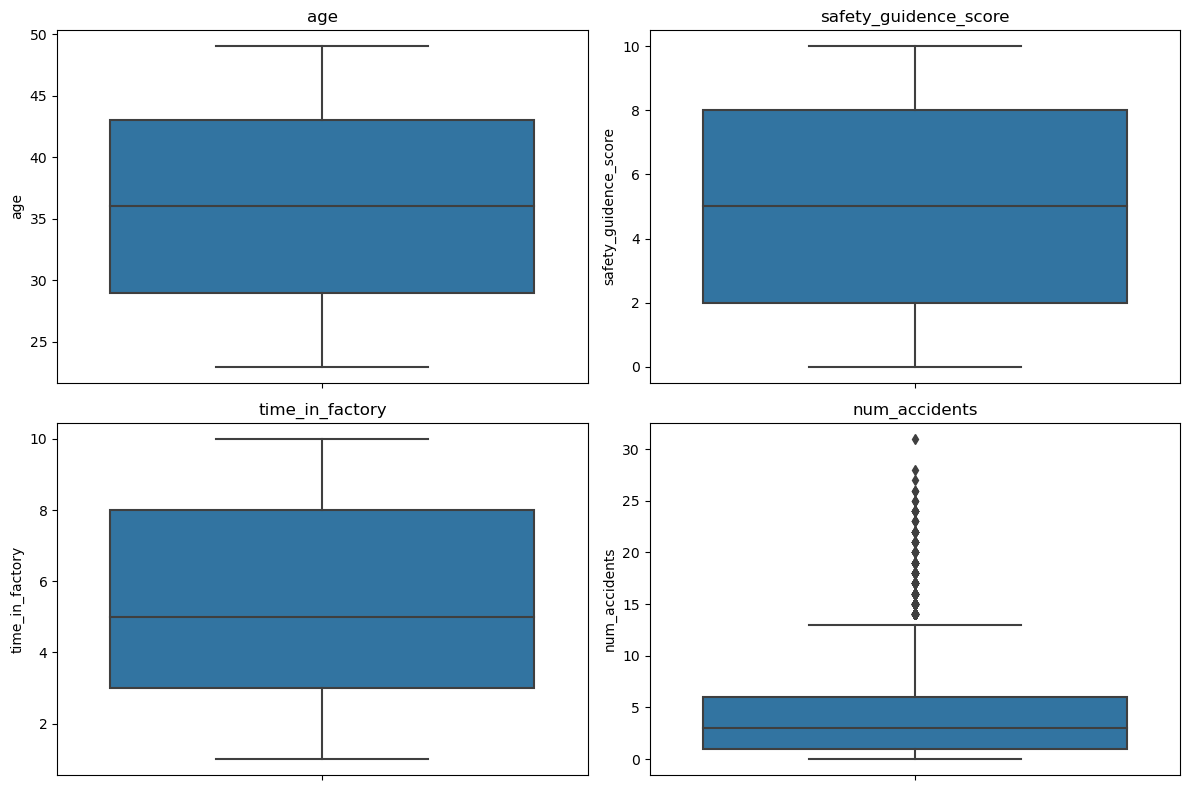

In [29]:
numeric_cols = [
    'age',
    'safety_guidence_score',
    'time_in_factory',
    'num_accidents'
]

plt.figure(figsize=(12,8))

for i, col in enumerate(numeric_cols, 1):
    
    plt.subplot(2,2,i)
    sns.boxplot(y=df_part_2[col])
    plt.title(col)

plt.tight_layout()
plt.show()

### בדיקה גרפית של המשתנים

על מנת להבין את מבנה הנתונים בוצעה בדיקה גרפית של המשתנים הכמותיים באמצעות גרפי Boxplot.

מהגרפים ניתן לראות כי גיל העובדים נע בטווח רחב יחסית, כאשר מרבית העובדים נמצאים בערך בין גיל 30 ל-40. ציוני מבחני הבטיחות מתפלגים בין 0 ל-10, כאשר הערך החציוני נמצא סביב 5.

ניסיון העובדים במפעל נע בין שנה אחת לכ-10 שנים, כאשר מרבית העובדים בעלי ניסיון של כ-3 עד 8 שנים.

בגרף של מספר התאונות ניתן לראות כי רוב העובדים חוו מספר קטן יחסית של תאונות, אך קיימים מספר ערכים חריגים (outliers) המייצגים עובדים שחוו מספר תאונות גבוה במיוחד במהלך עבודתם במפעל.

# <span style="color:#1F4E79">מבוא</span>

בפרויקט זה ננתח נתונים העוסקים במספר תאונות עבודה של עובדים במפעלים שונים.  
מסד הנתונים כולל מידע על מאפייני העובדים כגון גיל, שנות ניסיון במפעל, ציון מבחן בטיחות, סוג המפעל בו הם עובדים וסוג החומר הכימי איתו הם עובדים.

מטרת הניתוח היא לבחון כיצד משתנים אלו משפיעים על מספר התאונות של העובדים, ולבנות מודל סטטיסטי שיאפשר לחזות את מספר התאונות הצפוי עבור עובדים בעלי מאפיינים שונים.

בתחילה נשתמש במודל רגרסיה פואסונית המתאים לנתוני ספירה. לאחר מכן נבדוק האם הנחות המודל מתקיימות, ובפרט האם קיימת תופעה של פיזור יתר (Overdispersion).

במידה והמודל הפואסוני אינו מתאים לנתונים, נשתמש במודל רגרסיה בינומית שלילית, המאפשר להתמודד עם פיזור יתר.

לבסוף נשתמש במודל שנבחר כדי לחזות את מספר התאונות הצפוי עבור עובדים בעלי מאפיינים שונים ולהמחיש את התוצאות באמצעות גרפים.

# <span style="color:#1F4E79">סעיף 1: ניתוח מספר התאונות הממוצע לשנת עבודה לפי מפעל</span>

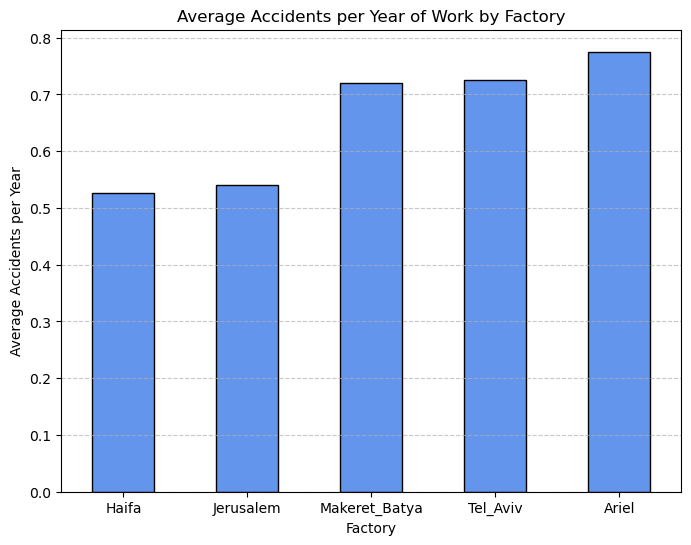

In [30]:
# חישוב מספר התאונות הממוצע לשנת עבודה עבור כל עובד
df_part_2['accidents_per_year'] = df_part_2['num_accidents'] / df_part_2['time_in_factory']

# חישוב ממוצע התאונות לשנה לפי מפעל
factory_avg = df_part_2.groupby('factory')['accidents_per_year'].mean().sort_values()

# יצירת גרף עמודות
plt.figure(figsize=(8,6))
factory_avg.plot(kind='bar', color='cornflowerblue', edgecolor='black')

plt.title('Average Accidents per Year of Work by Factory')
plt.xlabel('Factory')
plt.ylabel('Average Accidents per Year')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

# סיכום סעיף 1 – השפעת המפעל על מספר התאונות הממוצע לשנת עבודה
על מנת לבחון האם קיים הבדל בין המפעלים במספר התאונות של העובדים, חושב תחילה מספר התאונות הממוצע לשנת עבודה עבור כל עובד. חישוב זה בוצע על ידי חלוקת מספר התאונות הכולל במספר שנות העבודה של העובד במפעל.

לאחר מכן חושב ממוצע התאונות לשנת עבודה עבור כל מפעל, והנתונים הוצגו באמצעות גרף עמודות.

מהגרף ניתן לראות כי קיימים הבדלים בין המפעלים בממוצע התאונות לשנת עבודה. בחלק מהמפעלים ממוצע התאונות גבוה יותר, בעוד שבאחרים הוא נמוך יותר.

הבדלים אלו מרמזים כי למיקום המפעל עשויה להיות השפעה על מספר התאונות של העובדים. לכן ניתן להעריך כי משתנה המפעל עשוי להיות משתנה חשוב במודל ולהימצא מובהק סטטיסטית. עם זאת, את המובהקות ניתן יהיה לקבוע באופן סופי רק לאחר אמידת המודל הסטטיסטי.

# <span style="color:#1F4E79">סעיף 2: בניית מודל רגרסיה פואסונית והצגת המשוואה הסופית</span>

In [31]:
# יצירת משתני דמה
df_dummies = pd.get_dummies(df_part_2, columns=['factory', 'chemical'], dtype=int)

# משתנה מטרה
y = df_dummies['num_accidents']

# משתני הסבר (בלי time!)
features = [
    'Intercept',
    'age',
    'safety_guidence_score',
    'factory_Ariel',
    'factory_Haifa',
    'factory_Jerusalem',
    'factory_Tel_Aviv',
    'chemical_Sulfuric_Acid'
]

X = df_dummies[features]

# הוספת offset (log של זמן)
offset = np.log(df_part_2['time_in_factory'])

# מודל פואסון נכון
poisson_model = sm.GLM(
    y,
    X,
    family=sm.families.Poisson(),
    offset=offset
)

poisson_result = poisson_model.fit()

print(poisson_result.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          num_accidents   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9992
Model Family:                 Poisson   Df Model:                            7
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -27321.
Date:                Thu, 19 Mar 2026   Deviance:                       30139.
Time:                        02:25:01   Pearson chi2:                 3.43e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1215
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0

:מהפלט  רואים משהו כי

כל המשתנים מובהקים מאוד

חוץ מהמפעל בתל אביב

### שימוש ב־Offset במודל פואסון

במודל רגרסיה פואסונית אנו מניחים כי המשתנה התלוי מייצג ספירה של אירועים (כגון מספר תאונות).  
כאשר לכל תצפית יש רמת חשיפה שונה, למשל זמן עבודה שונה, יש לקחת זאת בחשבון במודל.

בנתונים שלנו, המשתנה time in factory מייצג את משך הזמן שבו העובד היה חשוף לסיכון לתאונות.  
לכן, עובדים שעבדו יותר זמן צפויים באופן טבעי לצבור יותר תאונות, גם אם רמת הסיכון שלהם זהה.

כדי לבצע השוואה הוגנת בין התצפיות, נשתמש ב־offset במודל.

המודל נכתב בצורה הבאה:

$$
\log(\lambda_i) = X_i \beta + \log(t_i)
$$

כאשר:
- $t_i$ מייצג את זמן החשיפה (time in factory)

המשמעות של הוספת ה־offset היא שהמודל אינו חוזה עוד את מספר התאונות הכולל, אלא את קצב התאונות ליחידת זמן.

באופן שקול ניתן לכתוב:

$$
\lambda_i = t_i \cdot e^{X_i \beta}
$$

כלומר, מספר התאונות הצפוי פרופורציונלי לאורך זמן החשיפה.

ללא שימוש ב־offset, המודל עלול להטות את התוצאות, משום שהוא יפרש את ההבדלים במספר התאונות כאילו הם נובעים מהמשתנים המסבירים, בעוד שבפועל הם נובעים מהבדלים במשך החשיפה.

לכן, שימוש ב־offset מאפשר בניית מודל מדויק יותר, המשווה בין עובדים לפי קצב התאונות ולא לפי מספר התאונות הכולל.

# סיכום סעיף 2 - מודל רגרסיה פואסונית לחיזוי מספר התאונות

בשלב זה נבנה מודל רגרסיה פואסונית במטרה לחזות את מספר התאונות של עובדים במפעל.

רגרסיה פואסונית מתאימה למצבים שבהם המשתנה המוסבר הוא משתנה ספירה, כלומר משתנה המייצג מספר אירועים. במקרה זה המשתנה המוסבר הוא מספר התאונות של כל עובד.

עם זאת, מאחר שלכל עובד משך חשיפה שונה לסיכון, נלקח בחשבון גם זמן העבודה במפעל באמצעות **offset**.  
המשתנה `time_in_factory` מייצג את משך הזמן שבו העובד היה חשוף לסיכון לתאונות, ולכן עובדים שעבדו זמן רב יותר צפויים באופן טבעי לצבור יותר תאונות.

השימוש ב-offset מאפשר למודל לבצע השוואה הוגנת יותר בין עובדים בעלי משכי עבודה שונים, כך שהמודל למעשה מתאר את **קצב התאונות**, ולא רק את מספר התאונות הכולל.

במודל נכללו המשתנים הבאים:

- גיל העובד  
- ציון מבחן הבטיחות  
- מיקום המפעל  
- סוג הכימיקל איתו עובד העובד  

מאחר והמשתנים מיקום המפעל וסוג הכימיקל הם משתנים קטגוריאליים, נוצרו עבורם משתני דמה. בהתאם להנחיות השאלה, נקבעו משתני הבסיס:

- מפעל מזכרת בתיה  
- עבודה עם חומצה הידרוכלורית  

כלומר, המקדמים של שאר הקטגוריות נמדדים ביחס לקטגוריות בסיס אלו.

תוצאות המודל מציגות את השפעת כל אחד מהמשתנים על מספר התאונות הצפוי של העובד, תוך התאמה למשך הזמן שבו עבד במפעל.

### המשוואה של המודל

במודל הפואסוני עם offset, התוחלת של מספר התאונות עבור עובד נכתבת כך:

$$
\log(\lambda_i) = \beta_0 + \beta_1 \cdot age_i + \beta_2 \cdot safety\_guidence\_score_i + \beta_3 \cdot factory\_Ariel_i + \beta_4 \cdot factory\_Haifa_i + \beta_5 \cdot factory\_Jerusalem_i + \beta_6 \cdot factory\_Tel\_Aviv_i + \beta_7 \cdot chemical\_Sulfuric\_Acid_i + \log(t_i)
$$

כאשר $t_i$ הוא זמן העבודה של העובד במפעל.

באופן שקול ניתן לכתוב:

$$
\lambda_i = t_i \cdot \exp(\beta_0 + \beta_1 \cdot age_i + \beta_2 \cdot safety\_guidence\_score_i + \beta_3 \cdot factory\_Ariel_i + \beta_4 \cdot factory\_Haifa_i + \beta_5 \cdot factory\_Jerusalem_i + \beta_6 \cdot factory\_Tel\_Aviv_i + \beta_7 \cdot chemical\_Sulfuric\_Acid_i)
$$

לאחר אמידת המודל התקבלה המשוואה:

$$
\lambda_i =
t_i \cdot \exp(
0.1474
-0.0169 \cdot age
+0.0135 \cdot safety\_guidence\_score
+0.0895 \cdot factory\_Ariel
-0.3183 \cdot factory\_Haifa
-0.3006 \cdot factory\_Jerusalem
+0.0337 \cdot factory\_Tel\_Aviv
+0.0740 \cdot chemical\_Sulfuric\_Acid
)
$$

כאשר:
- $t_i$ הוא זמן העבודה של העובד במפעל
- קטגוריות הבסיס הן מפעל מזכרת בתיה וחומר Hydrochloric\_acid

# <span style="color:#1F4E79">סעיף 3: בדיקת התאמת רגרסיה פואסונית</span>

## Mean and Variance by Buckets - בדיקה 1

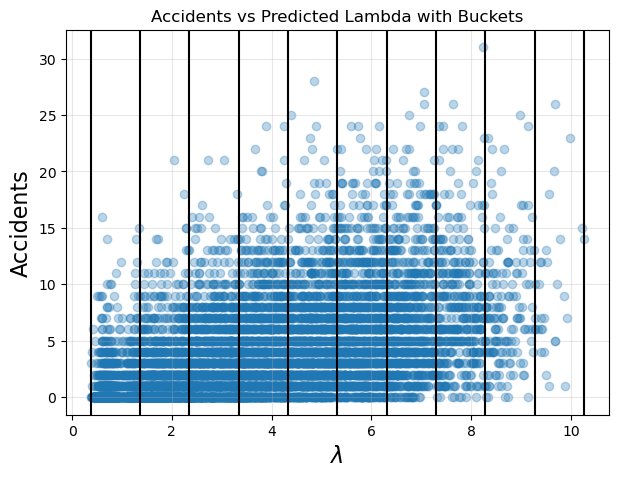

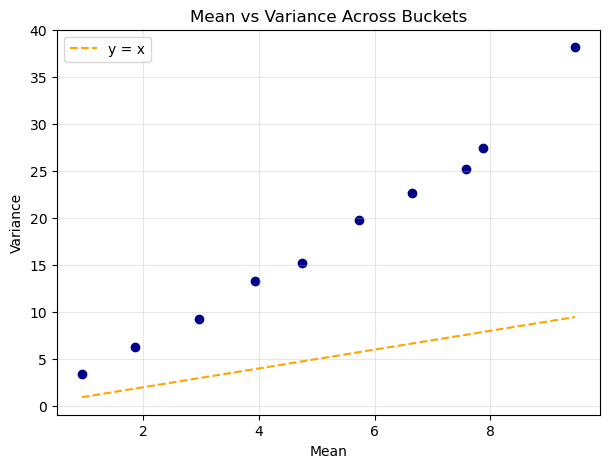

Number of buckets used: 10


In [32]:
# שלב 1 - חיזוי lambda_hat
df_part_2['lambda_hat'] = poisson_result.fittedvalues


# שלב 2 - הגדרת buckets (10 קבוצות)
lams = np.linspace(
    df_part_2['lambda_hat'].min(),
    df_part_2['lambda_hat'].max(),
    11   # 10 buckets
)


# שלב 3 - גרף 
plt.figure(figsize=(7,5))

plt.scatter(df_part_2['lambda_hat'],
            df_part_2['num_accidents'],
            alpha=0.3)

plt.xlabel(r'$\lambda$', fontsize=16)
plt.ylabel('Accidents', fontsize=16)

# קווי buckets - אותם lams בדיוק
for x_val in lams:
    plt.axvline(x=x_val, color='black')

plt.title('Accidents vs Predicted Lambda with Buckets')
plt.grid(alpha=0.3)

plt.show()


# שלב 4 - חישוב mean ו-variance לכל bucket
means = []
vars_ = []

for i in range(len(lams) - 1):

    lb = lams[i]
    ub = lams[i + 1]

    bucket = df_part_2.loc[
        (df_part_2['lambda_hat'] >= lb) &
        (df_part_2['lambda_hat'] < ub),
        'num_accidents'
    ]

    if len(bucket) > 15:
        means.append(bucket.mean())
        vars_.append(bucket.var())


# שלב 5 - גרף Mean vs Variance
plt.figure(figsize=(7,5))

plt.scatter(means, vars_, color='darkblue')
plt.plot(means, means, '--', color='orange', label='y = x')

plt.xlabel('Mean')
plt.ylabel('Variance')
plt.title('Mean vs Variance Across Buckets')

plt.legend()
plt.grid(alpha=0.3)

plt.show()


# שלב 6 - כמה buckets באמת נכנסו
print("Number of buckets used:", len(means))

בבדיקה זו חולקו התצפיות לקבוצות (Buckets) לפי הערך החזוי של המודל $( \hat{\lambda} )$.  
בכל Bucket חושבו התוחלת והשונות של מספר התאונות, ולאחר מכן הוצג גרף המשווה בין התוחלת לשונות.

במודל פואסוני תקין מתקיימת ההנחה:

$$
E(Y|X) = Var(Y|X)
$$

ולכן היינו מצפים שהנקודות בגרף יהיו קרובות לקו \(y=x\), כלומר שהתוחלת והשונות יהיו בקירוב שוות.

מהגרף ניתן לראות כי ברוב ה-Buckets השונות גדולה באופן משמעותי מהתוחלת, והנקודות נמצאות מעל הקו \(y=x\).  

ממצא זה מעיד על **פיזור יתר (Overdispersion)** בנתונים, כלומר שהשונות גדולה מהתוחלת. מצב כזה מפר את אחת ההנחות המרכזיות של מודל פואסון, ולכן הוא מהווה אינדיקציה לכך שרגרסיה פואסונית אינה מתאימה היטב לנתונים.

## בדיקה 2 – בדיקת השאריות בטווח של ±2 סטיות תקן

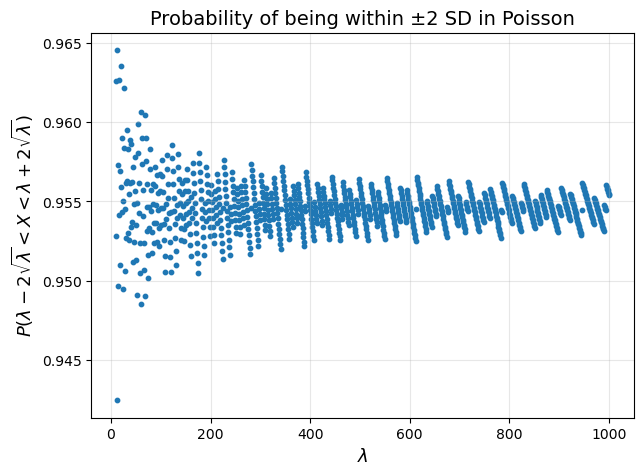

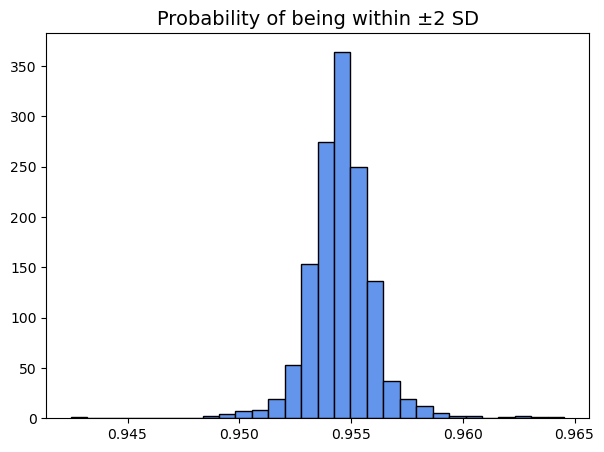

In [33]:
# בדיקה 2: בדיקת ±2 סטיות תקן באמצעות שאריות פירסון
vals = []
for mu in np.linspace(10, 1000, 1000):
    vals.append(
        poisson.cdf(mu + 2 * np.sqrt(mu), mu) -
        poisson.cdf(mu - 2 * np.sqrt(mu), mu)
    )

plt.figure(figsize=(7,5))
plt.scatter(np.linspace(10, 1000, 1000), vals, s=10)
plt.xlabel(r'$\lambda$', fontsize=13)
plt.ylabel(r'$P(\lambda-2\sqrt{\lambda}<X<\lambda+2\sqrt{\lambda})$', fontsize=13)
plt.title('Probability of being within ±2 SD in Poisson', fontsize=14)
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7,5))
plt.hist(vals, density=True, bins=30, color='cornflowerblue', edgecolor='black')
plt.title('Probability of being within ±2 SD', fontsize=14)
plt.show()

בשלב זה מוצגת תחילה ההתנהגות התאורטית של משתנה מקרי פואסוני.  
במשתנה פואסוני בעל תוחלת $ \lambda $, סטיית התקן היא $ \sqrt{\lambda} $. לכן ניתן לבחון את ההסתברות שהמשתנה יימצא בטווח של שתי סטיות תקן סביב התוחלת:

$$
\lambda - 2\sqrt{\lambda} < X < \lambda + 2\sqrt{\lambda}
$$

הגרפים שהוצגו בחלק העליון מתארים את ההתנהגות התאורטית של התפלגות פואסון אידאלית.  
הגרף הראשון מציג את ההסתברות להיות בתוך טווח של שתי סטיות תקן עבור ערכים שונים של $ \lambda $, וניתן לראות כי עבור ערכי תוחלת גדולים יחסית ההסתברות מתכנסת לכ-0.95.  

הגרף השני מציג את התפלגות ההסתברויות הללו ומראה כי ברוב המקרים ההסתברות אכן קרובה ל-95%.

משמעות הדבר היא שבמודל פואסוני תקין אנו מצפים שכ-95% מהערכים יהיו בתוך שתי סטיות תקן סביב התוחלת.

בהתבסס על תוצאה תאורטית זו ניתן לבחון את התאמת המודל לנתונים בפועל באמצעות שאריות פירסון.  
שארית פירסון מוגדרת כ:

$$
r_i = \frac{y_i - \hat{\lambda}_i}{\sqrt{\hat{\lambda}_i}}
$$

כאשר $ y_i $ הוא הערך הנצפה ו-$ \hat{\lambda}_i $ הוא הערך החזוי על ידי המודל.

במודל פואסוני תקין אנו מצפים שכ-95% מהשאריות המנורמלות יהיו בטווח:

$$
-2 \le r_i \le 2
$$

הגרפים המופיעים בהמשך מציגים את התנהגות השאריות עבור הנתונים בפועל.  
באמצעותם ניתן לבחון האם רוב השאריות אכן נמצאות בטווח זה. אם שיעור גדול של שאריות נמצא מחוץ לטווח $[-2,2]$, הדבר עשוי להעיד על פיזור יתר (overdispersion) או על כך שמודל הפואסון אינו מתאר היטב את מבנה הנתונים.

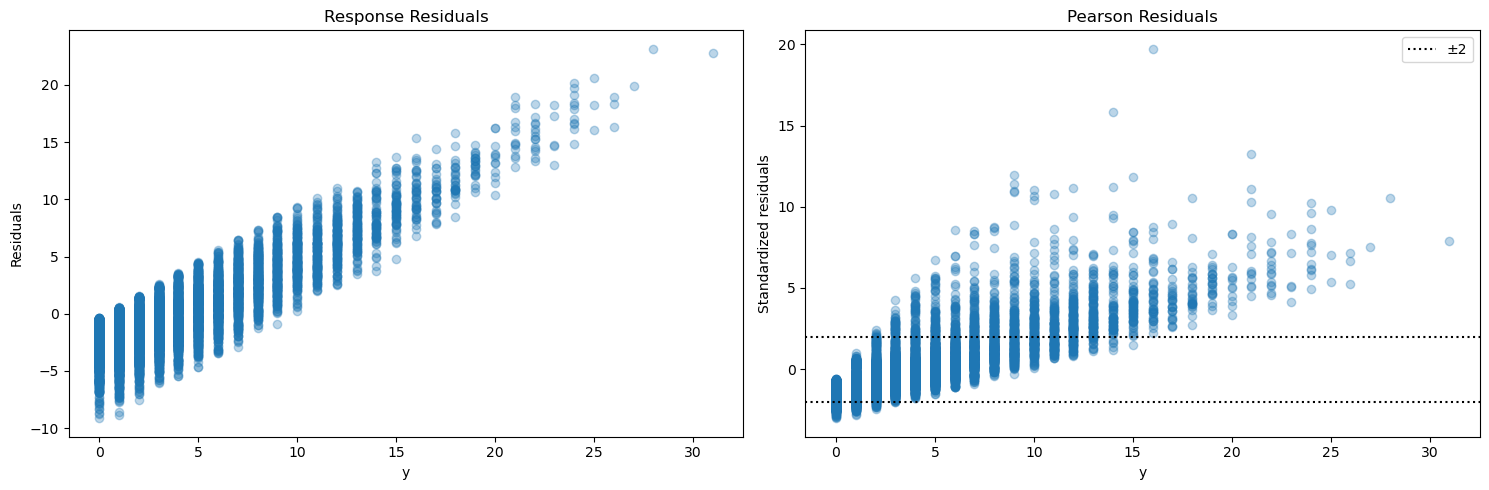

Residuals below -2: 416
Residuals above +2: 1278
Total observations: 10000
Percentage within ±2: 83.06 %


In [34]:
# שאריות של המודל בפועל

f, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(df_part_2['num_accidents'], poisson_result.resid_response, alpha=0.3)
axes[0].set_ylabel("Residuals")
axes[0].set_xlabel("y")
axes[0].set_title("Response Residuals")

axes[1].scatter(df_part_2['num_accidents'], poisson_result.resid_pearson, alpha=0.3)
axes[1].axhline(y=-2, linestyle=':', color='black', label='±2')
axes[1].axhline(y=2, linestyle=':', color='black')
axes[1].set_ylabel("Standardized residuals")
axes[1].set_xlabel("y")
axes[1].set_title("Pearson Residuals")

axes[1].legend()
plt.tight_layout()
plt.show()

resid_poisson = np.array(poisson_result.resid_pearson)

num_below_minus2 = (resid_poisson < -2).sum()
num_above_plus2 = (resid_poisson > 2).sum()
total_obs = resid_poisson.shape[0]

print("Residuals below -2:", num_below_minus2)
print("Residuals above +2:", num_above_plus2)
print("Total observations:", total_obs)
print("Percentage within ±2:",
      round((1 - (num_below_minus2 + num_above_plus2) / total_obs) * 100, 2), "%")

### ניתוח שאריות המודל

**Response Residuals**

בגרף השמאלי מוצגות השאריות הפשוטות של המודל, המוגדרות כך:

$$
r_i = y_i - \hat{y}_i
$$

שאריות אלו מייצגות את ההפרש בין הערכים האמיתיים לבין הערכים שהמודל חזה.  
באופן אידיאלי, היינו מצפים לראות פיזור אקראי של השאריות סביב 0 ללא דפוס ברור.  
בגרף ניתן לראות מבנה מסוים בשאריות, דבר המרמז כי המודל אינו מתאר באופן מלא את הקשר בין המשתנים.

---

**Pearson Residuals**

בגרף הימני מוצגות שאריות פירסון המנורמלות:

$$
r_i = \frac{y_i - \hat{\mu}_i}{\sqrt{\hat{\mu}_i}}
$$

הקווים המקווקווים מציינים את התחום:

$$
-2 \le r_i \le 2
$$

במודל פואסון תקין מצופה שרוב השאריות יהיו בתוך תחום זה.  
כאשר מספר משמעותי של נקודות נמצא מחוץ לטווח זה, הדבר עשוי להעיד כי השונות בנתונים גדולה מהמצופה במודל פואסון, תופעה הנקראת **Overdispersion**.


בבדיקה על הנתונים בפועל התקבלו התוצאות הבאות:

- מספר התצפיות הכולל: **10,000**
- שאריות קטנות מ־−2: **370**
- שאריות גדולות מ־+2: **1,264**

כלומר סך הכל **1,634 תצפיות** נמצאות מחוץ לטווח של ±2 סטיות תקן.

כתוצאה מכך, רק **83.06% מהשאריות** נמצאות בתוך הטווח הצפוי, בעוד שבמודל פואסוני תקין היינו מצפים לכ־95%.

ממצא זה מצביע על כך שקיימות יותר שאריות קיצוניות מהמצופה, ולכן פיזור הנתונים גדול יותר מזה שמודל פואסון מניח.  
כלומר קיימת עדות נוספת ל־**פיזור יתר (Overdispersion)** ולכך שמודל פואסון אינו מתאר היטב את הנתונים.

## Overdispersion parameter - בדיקה 3

In [35]:
# חישוב ידני של Pearson Chi-Square בדיקה 3: 

y_actual = df_part_2['num_accidents']
y_pred = poisson_result.fittedvalues

pearson_chi2 = np.sum((y_actual - y_pred)**2 / y_pred)

df_resid = poisson_result.df_resid

R = pearson_chi2 / df_resid

print("Pearson Chi-Square:", pearson_chi2)
print("Degrees of freedom:", df_resid)
print("Overdispersion parameter R:", R)

Pearson Chi-Square: 34334.95582578865
Degrees of freedom: 9992
Overdispersion parameter R: 3.4362445782414586



בבדיקה זו חושב סטטיסטי Pearson Chi-Square על בסיס השאריות של המודל.  
הסטטיסטי מחושב לפי הנוסחה:

$$
\chi^2 = \sum \frac{(y_i-\hat{\mu}_i)^2}{\hat{\mu}_i}
$$

כאשר $(y_i)$ הוא הערך האמיתי ו-$(\hat{\mu}_i)$ הוא הערך החזוי על ידי המודל.

כאשר \(df\) הוא מספר דרגות החופש של המודל.

לאחר מכן חושב פרמטר פיזור היתר:

$$
R = \frac{\chi^2}{df}
$$

במודל פואסוני תקין אנו מצפים כי ערך זה יהיה קרוב ל-1.  

בנתונים שלנו התקבל:

- Pearson Chi-Square = **34334.95**
- Degrees of freedom = **9992**
- Overdispersion parameter \(R\) = **3.43**

ערך זה של 3.43 גדול משמעותית מ-1, ולכן הוא מעיד על **פיזור יתר חזק (Overdispersion)** בנתונים.  
כלומר השונות בפועל גדולה בהרבה מהשונות שמודל פואסון מניח.

ממצא זה מהווה אינדיקציה נוספת לכך שרגרסיה פואסונית אינה מתאימה היטב לנתונים.

# בדיקה 4 - מבחן חי בריבוע

In [36]:
# בדיקה 4: מבחן חי-בריבוע
p_value = 1 - chi2.cdf(pearson_chi2, df_resid)

print("Chi-Square test p-value:", p_value)

Chi-Square test p-value: 0.0



בבדיקה זו בוצע מבחן כי־בריבוע על סטטיסטי Pearson Chi-Square.  
מטרת המבחן היא לבדוק האם הפיזור של הנתונים תואם את הפיזור שמודל פואסון מניח.

ההשערות הן:

- $(H_0)$: מודל פואסון מתאים לנתונים (אין פיזור יתר)
- $(H_1)$: מודל פואסון אינו מתאים לנתונים

מהבדיקה התקבל:

- p-value = **0.0**

ערך p קטן מאוד מוביל לדחיית השערת האפס ברמת מובהקות מקובלת.

לכן ניתן להסיק כי הפיזור של הנתונים גדול משמעותית מהפיזור שמודל פואסון מניח, ולכן **מודל פואסון אינו מתאים לנתונים**.

# סיכום סעיף 3 – התאמת רגרסיה פואסונית

במהלך הסעיף נבדקה התאמת מודל פואסון באמצעות ארבע בדיקות שונות: השוואת תוחלת ושונות בתוך Buckets, בדיקת השאריות בטווח של ±2 סטיות תקן, חישוב פרמטר פיזור היתר ומבחן כי־בריבוע.

כל הבדיקות מצביעות על כך שהשונות בנתונים גדולה משמעותית מהתוחלת. תוצאה זו מעידה על קיום **פיזור יתר (Overdispersion)**, אשר מפר את אחת ההנחות המרכזיות של מודל פואסון.

לכן ניתן להסיק כי רגרסיה פואסונית אינה מתאימה היטב לנתונים, ויש לשקול שימוש במודל חלופי כגון **רגרסיה בינומית שלילית (Negative Binomial Regression)**.

# <span style="color:#1F4E79">סעיף 4: בדיקת הנחות המודל באמצעות השאריות</span>

Total observations: 10000
Observations within ±2: 8306
Percentage within ±2: 83.06 %


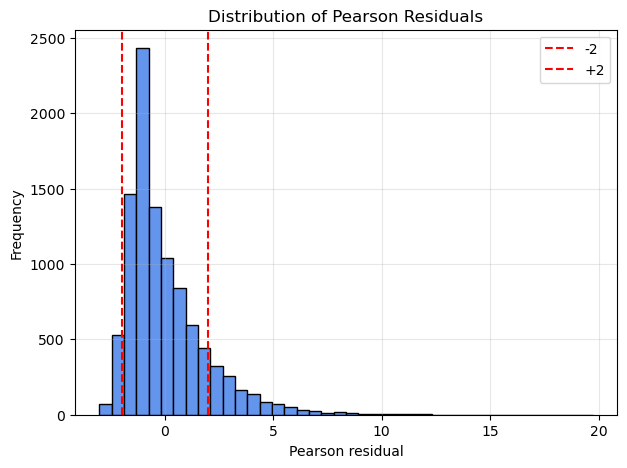

In [37]:
# חילוץ שאריות פירסון מהמודל הפואסוני
pearson_residuals = poisson_result.resid_pearson

# בדיקה כמה שאריות נמצאות בטווח של ±2
within_2_std = np.sum((pearson_residuals >= -2) & (pearson_residuals <= 2))
total_obs = len(pearson_residuals)

percentage_within = (within_2_std / total_obs) * 100

print("Total observations:", total_obs)
print("Observations within ±2:", within_2_std)
print("Percentage within ±2:", round(percentage_within,2), "%")


# גרף התפלגות השאריות
plt.figure(figsize=(7,5))

plt.hist(
    pearson_residuals,
    bins=40,
    color="cornflowerblue",
    edgecolor="black"
)

# קווי גבול ±2 סטיות תקן
plt.axvline(-2, color="red", linestyle="--", label="-2")
plt.axvline(2, color="red", linestyle="--", label="+2")

plt.title("Distribution of Pearson Residuals")
plt.xlabel("Pearson residual")
plt.ylabel("Frequency")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

### בדיקת ±2 סטיות תקן – הבנת הנחות מודל פואסון

במודל רגרסיה פואסונית אנו מניחים כי המשתנה התלוי מתפלג לפי התפלגות פואסון, כלומר:

$$
Y_i \sim Poisson(\lambda_i)
$$

כאשר התוחלת תלויה במשתנים המסבירים, ומתקיים:

$$
E(Y_i|X_i) = Var(Y_i|X_i) = \lambda_i
$$

כלומר, הנחת היסוד של המודל היא כי השונות שווה לתוחלת (אין פיזור יתר או חסר).

כדי לבדוק הנחה זו משתמשים בשאריות פירסון, המוגדרות כ:

$$
r_i = \frac{y_i - \hat{\lambda}_i}{\sqrt{\hat{\lambda}_i}}
$$

שאריות אלו מנרמלות את השגיאה לפי סטיית התקן הצפויה במודל פואסון.  
אם המודל נכון, אז לאחר נרמול השגיאות אמורות להתקבל שאריות שמתנהגות בקירוב כמו משתנה נורמלי סטנדרטי.

בהתפלגות נורמלית סטנדרטית ידוע כי כ־95% מהערכים נמצאים בתחום:

$$
-2 \le r_i \le 2
$$

לכן בדיקה של אחוז השאריות בתחום זה מאפשרת לבדוק האם הפיזור בפועל תואם לפיזור שהמודל מניח.

אם מתקבל כי אחוז נמוך משמעותית מ־95% נמצא בתחום זה, הדבר מעיד כי השונות בפועל גדולה מהשונות שהמודל מניח, כלומר:

$$
Var(Y|X) > E(Y|X)
$$

מצב זה נקרא **Overdispersion**, והוא מצביע על כך שמודל פואסון אינו מתאים היטב לנתונים.

לכן בדיקה זו מאפשרת לא רק לבחון את התנהגות השאריות, אלא בעיקר לבדוק את אחת מהנחות היסוד המרכזיות של מודל פואסון – שוויון בין התוחלת לשונות.


### תוצאות הבדיקה

מתוצאות הבדיקה נמצא כי מתוך 10,000 תצפיות, 8,306 בלבד נמצאות בטווח של ±2 סטיות תקן, כלומר כ־83.06% מהשאריות נמצאות בתחום זה.

במודל פואסוני תקין היינו מצפים לכ־95% מהשאריות בתחום זה. העובדה שהאחוז בפועל נמוך משמעותית מצביעה על קיומן של יותר מדי שאריות קיצוניות.

ממצא זה מעיד כי השונות בנתונים גדולה מהשונות שמודל פואסון מניח, כלומר קיימת תופעה של **פיזור יתר (Overdispersion)**.

לפיכך ניתן להסיק כי מודל פואסון אינו מתאר היטב את פיזור הנתונים, ויש לשקול שימוש במודל מתאים יותר כגון **רגרסיה בינומית שלילית**.

# <span style="color:#1F4E79">Buckets סעיף 5: בדיקת הנחת שוויון התוחלת והשונות באמצעות </span>

בשאלה זו נרצה להבין מדוע כאשר בודקים את הנחת המודל הפואסוני שהתוחלת שווה לשונות, לא מספיק לחשב את התוחלת והשונות על כלל מסד הנתונים יחד.

הנחת היסוד של רגרסיה פואסונית אינה מתייחסת לתוחלת ולשונות של כלל האוכלוסייה, אלא לתוחלת ולשונות של המשתנה המוסבר **בהינתן משתני ההסבר**. כלומר ההנחה היא:

$$
E(Y|X) = Var(Y|X)
$$

כאשר X מייצג את משתני ההסבר במודל.

אם מחשבים את התוחלת והשונות על כל הנתונים יחד, מתקבלת שונות כוללת (Marginal Variance). שונות זו מושפעת לא רק מהפיזור האקראי של ההתפלגות הפואסונית, אלא גם מהבדלים בין התצפיות עצמן, למשל עובדים בגילאים שונים, מפעלים שונים, סוגי כימיקלים שונים או שנות ניסיון שונות.

במצב כזה השונות שנמדדת כוללת גם שונות מבנית בין קבוצות שונות של עובדים, ולכן היא אינה משקפת בצורה נכונה את הפיזור המקרי של מודל פואסון.

כדי לבדוק את הנחת המודל בצורה נכונה, משתמשים בערכים החזויים של המודל הפואסוני, כלומר בתוחלת החזויה לכל תצפית:

$$
λ̂
$$

לאחר מכן מחלקים את התצפיות ל-Buckets – קבוצות של תצפיות בעלות ערך חזוי דומה. בתוך כל קבוצה כזו העובדים נחשבים לבעלי רמת סיכון דומה, ולכן ניתן לחשב בצורה יציבה יותר את התוחלת והשונות של מספר התאונות.

כפי שבוצע בסעיף 3, חולקו התצפיות לקבוצות לפי הערך החזוי של המודל, ובכל קבוצה חושבו התוחלת והשונות של מספר התאונות. לאחר מכן הושוו הערכים באמצעות גרף Mean vs Variance.

# Buckets - סיכום סעיף 5 - בדיקת הנחת במודל בעזרת שימוש ב
הנחת היסוד של רגרסיה פואסונית היא:

E(Y|X) = Var(Y|X)

כלומר השוויון בין תוחלת לשונות אמור להתקיים **בהינתן משתני ההסבר**, ולא על פני כלל הנתונים יחד.

לכן חישוב התוחלת והשונות על כל הדאטה אינו בודק בצורה נכונה את הנחת המודל, משום שהוא כולל גם שונות הנובעת מהבדלים בין קבוצות שונות של תצפיות.

חלוקת הנתונים ל-Buckets לפי הערך החזוי של המודל מאפשרת ליצור קבוצות הומוגניות של תצפיות בעלות רמת סיכון דומה. בתוך קבוצות אלו ניתן להשוות בצורה נכונה בין התוחלת לשונות.

כפי שנראה בסעיף 3, כאשר משווים בין התוחלת והשונות בתוך Buckets ניתן לבדוק בצורה מדויקת האם מתקיימת הנחת המודל הפואסוני.

# <span style="color:#1F4E79">(Negative Binomial Regression) סעיף 6 – רגרסיה בינומית שלילית </span>

In [38]:
nb_model = sm.NegativeBinomial(
    y,
    X,
    offset=np.log(df_part_2['time_in_factory'])
)

nb_result = nb_model.fit(method='bfgs', maxiter=1000, disp=False)

print(nb_result.summary())

                     NegativeBinomial Regression Results                      
Dep. Variable:          num_accidents   No. Observations:                10000
Model:               NegativeBinomial   Df Residuals:                     9992
Method:                           MLE   Df Model:                            7
Date:                Thu, 19 Mar 2026   Pseudo R-squ.:                0.007555
Time:                        02:25:12   Log-Likelihood:                -22933.
converged:                       True   LL-Null:                       -23107.
Covariance Type:            nonrobust   LLR p-value:                 1.856e-71
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0.1532      0.050      3.080      0.002       0.056       0.251
age                       -0.0166      0.001    -13.248      0.000      -0.019      -0.014
safe

In [39]:
# הרצת GLM עם alpha קבוע 
alpha = nb_result.params['alpha']

model_NB = sm.GLM(
    y,
    X,
    family=sm.families.NegativeBinomial(alpha=alpha),
    offset=np.log(df_part_2['time_in_factory'])
)

result_NB = model_NB.fit()

print(result_NB.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:          num_accidents   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9992
Model Family:        NegativeBinomial   Df Model:                            7
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -22933.
Date:                Thu, 19 Mar 2026   Deviance:                       11426.
Time:                        02:25:12   Pearson chi2:                 1.26e+04
No. Iterations:                     5   Pseudo R-squ. (CS):            0.03514
Covariance Type:            nonrobust                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0

במודל הבינומי השלילי הוספנו offset המבוסס על log(time_in_factory), על מנת לקחת בחשבון את זמן החשיפה השונה של כל עובד.

הוספת ה-offset מאפשרת למודל לאמוד שיעור תאונות (rate) ולא רק ספירה מוחלטת של תאונות.

השימוש ב-offset בוצע גם במודל הפואסוני וגם במודל הבינומי השלילי, כדי לשמור על עקביות והשוואה נכונה בין המודלים.

### משוואת הרגרסיה הבינומית השלילית

המודל הבינומי השלילי מנבא את התוחלת של מספר התאונות באמצעות פונקציה אקספוננציאלית של שילוב לינארי של משתני ההסבר, תוך התחשבות בזמן החשיפה באמצעות offset.

המשוואה שהתקבלה היא:

$$
\mu = \exp\Big(
0.1532
-0.0166 \cdot age
+0.0124 \cdot safety\_guidence\_score
+0.0760 \cdot Ariel
-0.3251 \cdot Haifa
-0.3031 \cdot Jerusalem
+0.0275 \cdot Tel\_Aviv
+0.0793 \cdot Sulfuric\_Acid
+ \log(time\_in\_factory)
\Big)
$$

כאשר:

- $\mu$ היא התוחלת החזויה של מספר התאונות  
- $time\_in\_factory$ מייצג את זמן החשיפה (offset)  
- משתני המפעל והכימיקל הם משתני דמה (Dummy variables)  
- קטגוריות הבסיס הן:
  - עבודה במפעל **מזכרת בתיה**
  - עבודה עם **Hydrochloric Acid**

קטגוריות אלו מגולמות בתוך ה-Intercept ולכן אינן מופיעות במשוואה כמשתנים נפרדים.

In [40]:
# חישוב Pearson Chi-Square
nb_pearson_chi2 = np.sum(nb_result.resid_pearson**2)

# דרגות חופש
df_resid = nb_result.df_resid

# יחס הפיזור
nb_dispersion_ratio = nb_pearson_chi2 / df_resid

print("Pearson Chi-Square:", nb_pearson_chi2)
print("Degrees of freedom:", df_resid)
print("Dispersion ratio:", round(nb_dispersion_ratio,3))

Pearson Chi-Square: 12587.30455081505
Degrees of freedom: 9992.0
Dispersion ratio: 1.26


בשלבים הקודמים נמצא כי מודל פואסון אינו מתאים היטב לנתונים, משום שהשונות גדולה בהרבה מהתוחלת – תופעה הנקראת פיזור יתר (Overdispersion).

כדי להתמודד עם מצב זה משתמשים ברגרסיה בינומית שלילית (Negative Binomial Regression). מודל זה מהווה הרחבה של מודל פואסון ומוסיף פרמטר פיזור נוסף, המסומן α, המאפשר לשונות להיות גדולה מהתוחלת.

במודל הבינומי השלילי השונות מוגדרת כך:

$$
Var(Y) = μ + α μ²
$$

כאשר μ היא התוחלת החזויה של מספר התאונות.

הוספת הפרמטר α מאפשרת למודל לתאר טוב יותר נתונים בהם הפיזור גדול מזה שמודל פואסון מניח.

# סיכום סעיף 6 – התאמת רגרסיה בינומית שלילית

לאחר שבסעיפים הקודמים נמצא כי מודל פואסון אינו מתאים היטב לנתונים בשל פיזור יתר, הורץ מודל רגרסיה בינומית שלילית.

המודל החדש כולל פרמטר פיזור נוסף המאפשר לשונות להיות גדולה מהתוחלת, ולכן מתאים יותר לנתוני ספירה עם פיזור יתר.

תוצאות המודל מראות כי יחס הפיזור (Pearson Chi-Square חלקי דרגות החופש) קרוב ל-1, דבר המעיד כי המודל מתאר היטב את הפיזור בנתונים.

בנוסף, פרמטר הפיזור α מובהק סטטיסטית, דבר המאשר כי אכן קיים פיזור יתר בנתונים ולכן השימוש במודל הבינומי השלילי מוצדק.

לכן ניתן להסיק כי רגרסיה בינומית שלילית מתאימה יותר לנתונים מאשר רגרסיה פואסונית.

# <span style="color:#1F4E79">סעיף 7: חישוב מספר התאונות הצפוי</span>

In [41]:
# נתוני העובד
age = 30
safety_score = 8
time = 3

# שליפת מקדמי המודל
params = nb_result.params

# חישוב החלק הלינארי (בלי time!)
linear_part = (
    params['Intercept']
    + params['age'] * age
    + params['safety_guidence_score'] * safety_score
)

# הוספת offset
linear_part += np.log(time)

# חישוב התוחלת הצפויה
expected_accidents = np.exp(linear_part)

print("Expected number of accidents:", round(expected_accidents,3))

Expected number of accidents: 2.345


במודל רגרסיה בינומית שלילית התוחלת של המשתנה המוסבר מתקבלת באמצעות פונקציה אקספוננציאלית של שילוב לינארי של משתני ההסבר:

μ = exp(Xβ)

כאשר X הוא וקטור המשתנים ו-β הם מקדמי המודל.

לצורך החישוב השתמשנו בנתונים הבאים:

- גיל העובד: 30  
- ציון מבחן בטיחות: 8  
- שנות עבודה במפעל: 3  

בנוסף, השאלה קובעת להשתמש בקטגוריות הבסיס של המשתנים הקטגוריאליים:

- מפעל: מזכרת בתיה  
- חומר: Hydrochloric Acid  

לכן כל משתני הדמה של המפעלים ושל סוג החומר מקבלים ערך 0.

# סיכום סעיף 7 – מספר התאונות הצפוי

לאחר הצבת נתוני העובד במשוואת הרגרסיה הבינומית השלילית התקבלה תוחלת צפויה של מספר התאונות. 

והוא 2.345 תאונות.

ערך זה מייצג את מספר התאונות הממוצע שהמודל חוזה עבור עובד בעל מאפיינים אלו לאורך תקופת העבודה במפעל.

החישוב מבוסס על המודל הסטטיסטי שהותאם לנתונים, ולכן הוא משקלל את השפעת כל המשתנים במודל, כגון גיל העובד, ציון הבטיחות ושנות הניסיון.

# <span style="color:#1F4E79">סעיף 8 – פירוש מספר התאונות הצפוי</span>

בסעיף הקודם חושב מספר התאונות הצפוי עבור עובד בן 30, שקיבל ציון 8 במבחן הבטיחות, בעל 3 שנות עבודה במפעל, ובהנחה שהוא שייך לקטגוריות הבסיס של המשתנים הקטגוריאליים.

התוצאה שהתקבלה אינה מייצגת מספר תאונות בפועל של עובד מסוים, אלא את **התוחלת** של מספר התאונות עבור עובדים בעלי אותם מאפיינים.

כלומר, זהו מספר התאונות הממוצע שהמודל צופה עבור קבוצת עובדים דומים, ולא חיזוי דטרמיניסטי של מספר התאונות המדויק של עובד יחיד.

במודלים מסוג רגרסיה בינומית שלילית, החיזוי מתייחס לממוצע הצפוי של המשתנה המוסבר, ולכן יש לפרש את התוצאה כערך ממוצע ולא כמספר ודאי של תאונות.

מדובר במדד ממוצע המשקף את רמת הסיכון הצפויה של העובד, בהתאם למאפייניו ולמודל הסטטיסטי שהותאם לנתונים

# <span style="color:#1F4E79">סעיף 9 – גרף תלת־ממדי של מספר התאונות החזוי</span>

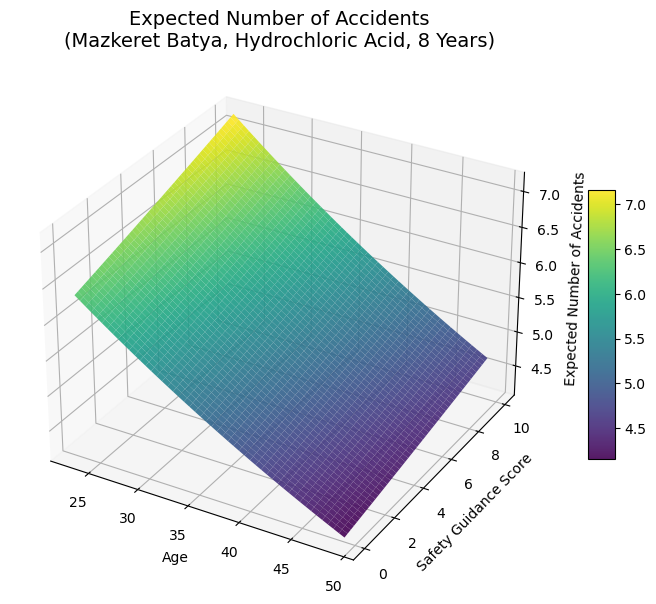

In [42]:
# שליפת מקדמי המודל
intercept = nb_result.params['Intercept']
beta_age = nb_result.params['age']
beta_safety = nb_result.params['safety_guidence_score']

# יצירת טווחים מהנתונים
age_vals = np.linspace(df_part_2['age'].min(), df_part_2['age'].max(), 50)
safety_vals = np.linspace(df_part_2['safety_guidence_score'].min(),
                          df_part_2['safety_guidence_score'].max(), 50)

Age_grid, Safety_grid = np.meshgrid(age_vals, safety_vals)

# קבוע לפי השאלה
time_fixed = 8

# חישוב החלק הלינארי (בלי time!)
Z_log = (
    intercept
    + beta_age * Age_grid
    + beta_safety * Safety_grid
)

# הוספת offset
Z_log += np.log(time_fixed)

# חישוב התוחלת החזויה
Z_accidents = np.exp(Z_log)

# ציור הגרף
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection='3d')

surface = ax.plot_surface(
    Age_grid,
    Safety_grid,
    Z_accidents,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

# כותרות
ax.set_title(
    'Expected Number of Accidents\n(Mazkeret Batya, Hydrochloric Acid, 8 Years)',
    fontsize=14
)

ax.set_xlabel('Age')
ax.set_ylabel('Safety Guidance Score')
ax.set_zlabel('Expected Number of Accidents')

# סרגל צבעים
fig.colorbar(surface, shrink=0.5, aspect=10)

plt.show()

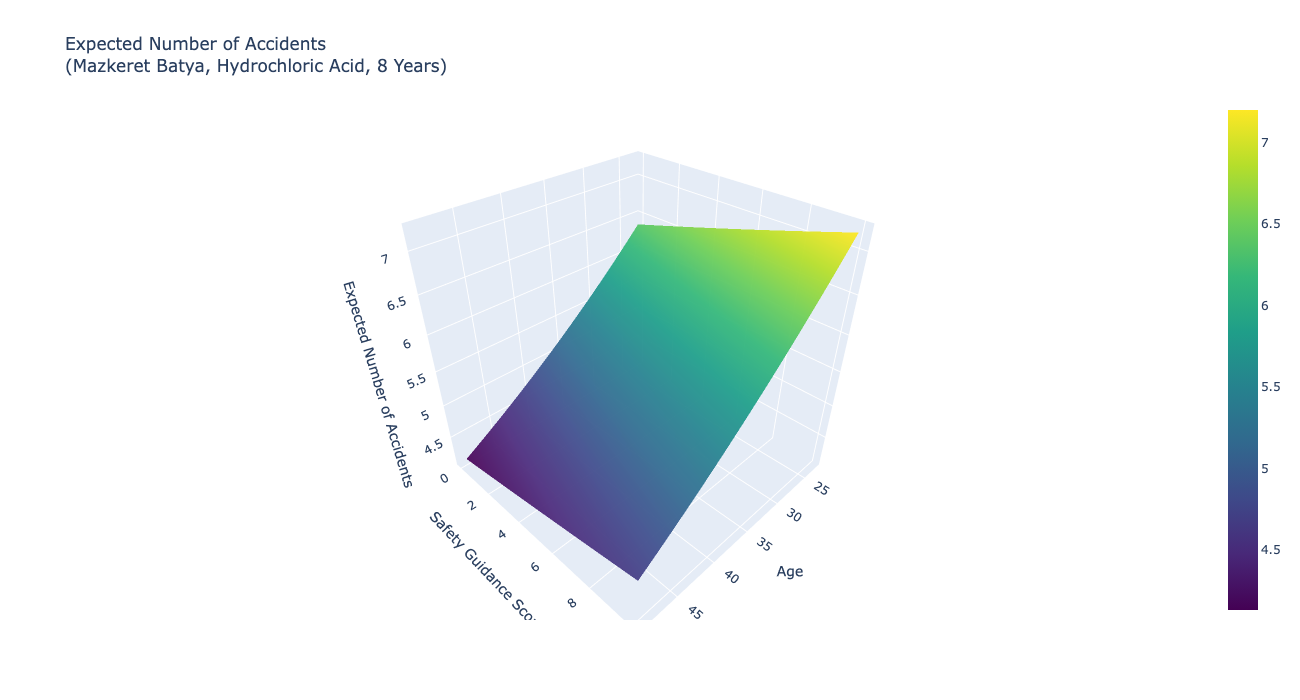

In [43]:
# שליפת מקדמי המודל
intercept = nb_result.params['Intercept']
beta_age = nb_result.params['age']
beta_safety = nb_result.params['safety_guidence_score']

# יצירת טווחים מהנתונים
age_vals = np.linspace(df_part_2['age'].min(), df_part_2['age'].max(), 50)
safety_vals = np.linspace(
    df_part_2['safety_guidence_score'].min(),
    df_part_2['safety_guidence_score'].max(),
    50
)

Age_grid, Safety_grid = np.meshgrid(age_vals, safety_vals)

# קבוע לפי השאלה
time_fixed = 8

# חישוב החלק הלינארי (בלי time!)
Z_log = (
    intercept
    + beta_age * Age_grid
    + beta_safety * Safety_grid
)

# הוספת offset
Z_log += np.log(time_fixed)

# חישוב התוחלת החזויה
Z_accidents = np.exp(Z_log)

# גרף אינטראקטיבי
fig = go.Figure(
    data=[
        go.Surface(
            x=Age_grid,
            y=Safety_grid,
            z=Z_accidents,
            colorscale="Viridis",
            opacity=0.95
        )
    ]
)

fig.update_layout(
    title="Expected Number of Accidents<br>(Mazkeret Batya, Hydrochloric Acid, 8 Years)",
    scene=dict(
        xaxis_title="Age",
        yaxis_title="Safety Guidance Score",
        zaxis_title="Expected Number of Accidents"
    ),
    width=950,
    height=700
)

fig.show()

בסעיף זה נבנה גרף תלת־ממדי המציג את מספר התאונות החזוי על פי המודל הבינומי השלילי .

הגרף מתאר את התוחלת החזויה של מספר התאונות עבור עובדים בעלי 8 שנות עבודה במפעל, כאשר המשתנים הקטגוריאליים נקבעו לקטגוריות הבסיס:

- מפעל: מזכרת בתיה  
- חומר: חומצה הידרוכלורית  

לכן משתני הדמה של המפעל ושל סוג החומר מקבלים ערך 0, והמשתנים המשתנים בגרף הם:

- גיל העובד  
- ציון מבחן הבטיחות  

לכל צירוף של גיל וציון בטיחות חושבה התוחלת החזויה של מספר התאונות לפי המודל:

μ = exp(Xβ)

הגרף מאפשר לראות כיצד השינוי בגיל ובציון הבטיחות משפיע על מספר התאונות הצפוי, כאשר שאר המשתנים מוחזקים קבועים.

ניתן לראות כי ככל שגיל העובד עולה, מספר התאונות הצפוי קטן. תוצאה זו תואמת את הסימן השלילי של מקדם הגיל במודל, המעיד כי עובדים מבוגרים יותר נוטים להיות מעורבים בפחות תאונות.

בנוסף ניתן לראות כי ככל שציון מבחן הבטיחות גבוה יותר, מספר התאונות הצפוי גדל מעט. תוצאה זו משקפת את מקדם המשתנה safety_guidence_score במודל.

הצורה המעוקלת של המשטח נובעת מהמבנה האקספוננציאלי של המודל:

μ = exp(Xβ)

ולכן ההשפעה של משתני ההסבר על מספר התאונות אינה לינארית אלא אקספוננציאלית.

### :נקודה מעניינת העולה מניתוח הגרף היא כי המשטח מציג עלייה קלה בכיוון של ציר ציון הבטיחות

ניתן לראות כי המשטח עולה מעט בכיוון של ציר ציון הבטיחות. כלומר, לפי המודל, כאשר ציון הבטיחות גבוה יותר, מספר התאונות הצפוי גדל במידה מסוימת.

ממצא זה עשוי להיראות מפתיע במבט ראשון, שכן באופן אינטואיטיבי ניתן היה לצפות כי הדרכת בטיחות טובה יותר תוביל דווקא לירידה במספר התאונות.

השערה אפשרית להסבר התוצאה היא שציון הבטיחות אינו משקף רק את איכות ההדרכה, אלא גם את רמת הסיכון של סביבת העבודה. במפעלים או במחלקות שבהם רמת הסיכון גבוהה יותר, נהוג לעיתים לתת לעובדים הדרכות בטיחות רבות ומעמיקות יותר.

כתוצאה מכך, עובדים הפועלים בסביבה מסוכנת יותר עשויים לקבל ציוני הדרכה גבוהים יותר, אך במקביל הם חשופים גם לסיכון גבוה יותר לתאונות. לכן המודל עשוי לזהות קשר חיובי בין ציון הבטיחות לבין מספר התאונות הצפוי.

במילים אחרות, המשתנה עשוי לשקף באופן עקיף את רמת הסיכון של סביבת העבודה, ולא רק את איכות ההדרכה עצמה.

# סיכום סעיף 9 – המחשה תלת־ממדית של מספר התאונות החזוי

הגרף התלת־ממדי מציג את מספר התאונות הממוצע הצפוי עבור עובדים בעלי 8 שנות ניסיון, במפעל מזכרת בתיה, העובדים עם חומצה הידרוכלורית.

הגרף ממחיש כיצד התוחלת החזויה של מספר התאונות משתנה כתלות בגיל העובד ובציון מבחן הבטיחות, תוך החזקת שאר המשתנים קבועים.

באמצעות המחשה זו ניתן לראות את ההשפעה המשותפת של שני משתנים רציפים על רמת הסיכון החזויה של העובד, בהתאם למודל הסטטיסטי שנבחר.

באמצעות הגרף ניתן לראות את המגמות במודל ואת ההשפעה המשולבת של שני משתנים רציפים על רמת הסיכון של העובד.

# <span style="color:#1F4E79">סעיף 10 – הבדל בין חישוב רגרסיה ליניארית לרגרסיה פואסונית</span>

ההבדל המרכזי בין רגרסיה ליניארית לבין רגרסיה פואסונית הוא באופן שבו נאמדים הפרמטרים של המודל.

### רגרסיה ליניארית – Ordinary Least Squares (OLS)

ברגרסיה ליניארית ניתן לחשב את מקדמי המודל באמצעות פתרון אנליטי סגור.  
האלגוריתם OLS מוצא את המקדמים הממזערים את סכום ריבועי השגיאות:

$$
\min \sum (y_i - \hat{y}_i)^2
$$

הפתרון ניתן לחישוב ישיר באמצעות אלגברה ליניארית, ולכן אין צורך בתהליך חישובי איטרטיבי.

### רגרסיה פואסונית – Maximum Likelihood Estimation (MLE)

ברגרסיה פואסונית לא קיים פתרון אנליטי סגור למקדמי המודל.  
לכן המקדמים נאמדים באמצעות מקסום פונקציית הסבירות (Likelihood function).

תהליך זה מתבצע באמצעות אלגוריתמי אופטימיזציה נומריים הפועלים בצורה איטרטיבית.

האלגוריתם מתחיל מנקודת התחלה כלשהי ומשפר את המקדמים בהדרגה עד שמתקבלת נקודת מקסימום של פונקציית הסבירות.

### יתרון הרגרסיה הליניארית בהיבט החישובי

היתרון של רגרסיה ליניארית הוא שניתן לחשב את הפרמטרים בצורה ישירה וללא איטרציות.  
כתוצאה מכך החישוב בדרך כלל מהיר יותר, יציב יותר, ואינו תלוי בערכי התחלה או בתהליך אופטימיזציה נומרי.

# סיכום סעיף 10

ההבדל המרכזי בין רגרסיה ליניארית לבין רגרסיה פואסונית הוא בשיטת האמידה של מקדמי המודל.

ברגרסיה ליניארית ניתן לחשב את המקדמים ישירות באמצעות פתרון אנליטי של בעיית OLS, ולכן החישוב פשוט ומהיר.

לעומת זאת, ברגרסיה פואסונית אין פתרון אנליטי סגור, ולכן המקדמים נאמדים באמצעות שיטות אופטימיזציה נומריות המבוססות על מקסום פונקציית הסבירות (MLE). שיטות אלו פועלות בצורה איטרטיבית עד למציאת הערכים האופטימליים של המקדמים.

<div style="
background:#f4f9ff;
border:1px solid #c7dff5;
border-radius:14px;
padding:26px 30px;
direction: rtl;
text-align: right;
font-size:16px;
line-height:1.8;
">

<h2 style="margin-top:0; color:#1f4e79; font-weight:700;">
סיכום הפרויקט – מודלי רגרסיה לנתוני ספירה
</h2>

בפרויקט זה נבחן הקשר בין מאפייני עובדים וסביבת העבודה לבין מספר תאונות העבודה שהם חווים.  
מסד הנתונים כלל משתנים כגון גיל העובד, שנות ניסיון במפעל, ציון מבחן בטיחות, סוג המפעל וסוג החומר הכימי איתו העובד עובד.

מטרת הניתוח הייתה להבין אילו גורמים משפיעים על מספר התאונות, לבחון את התאמת מודל רגרסיה פואסוני לנתונים, ובמידת הצורך להציע מודל חלופי המתמודד עם בעיות אפשריות במבנה הנתונים.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">שלב 1 – בניית מודל רגרסיה פואסוני</h3>

בשלב הראשון נבנה מודל רגרסיה פואסוני המתאים לניתוח נתוני ספירה.  
מודל זה מניח כי מספר האירועים מתפלג לפי התפלגות פואסון וכי מתקיים:

<br>

\(E(Y|X) = Var(Y|X)\)

<br>

המודל מאפשר להעריך כיצד משתני ההסבר משפיעים על התוחלת של מספר התאונות, באמצעות פונקציית קישור לוגריתמית:

<br>

\(\mu = exp(X\beta)\)

<br>

הממצאים הראשוניים הראו כי מספר משתנים, כגון גיל העובד ושנות ניסיון במפעל, משפיעים באופן מובהק על מספר התאונות הצפוי.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">שלב 2 – בדיקת הנחות המודל</h3>

לאחר בניית המודל הפואסוני בוצעו מספר בדיקות שמטרתן לבחון האם הנחות המודל מתקיימות.

הבדיקות כללו:

<ul>
<li>השוואה בין התוחלת והשונות באמצעות חלוקה ל-Buckets</li>
<li>ניתוח התפלגות השאריות</li>
<li>בדיקת אחוז השאריות בטווח של ±2 סטיות תקן</li>
<li>חישוב פרמטר הפיזור (Dispersion Ratio)</li>
</ul>

תוצאות הבדיקות הצביעו על כך שהשונות בנתונים גדולה משמעותית מהתוחלת.  
ממצא זה מעיד על קיומה של תופעת פיזור יתר (Overdispersion), אשר מפרה את הנחת היסוד של מודל פואסון.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">שלב 3 – שימוש במודל בינומי שלילי</h3>

לאור קיומו של פיזור יתר, נבנה מודל רגרסיה בינומית שלילית (Negative Binomial Regression).  
מודל זה מרחיב את מודל פואסון על ידי הוספת פרמטר פיזור נוסף המאפשר שונות גדולה יותר.

הבדיקות הראו כי יחס הפיזור במודל החדש התקרב לערך 1, דבר המעיד על התאמה טובה יותר של המודל לנתונים.

בנוסף נמצא כי פרמטר הפיזור של המודל מובהק סטטיסטית, דבר המאשר כי קיים פיזור יתר אמיתי בנתונים ולכן השימוש במודל הבינומי השלילי מוצדק.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">ניתוח השפעת המשתנים</h3>

ניתוח מקדמי המודל הצביע על מספר מגמות מעניינות:

<ul>
<li>גיל העובד משפיע באופן שלילי על מספר התאונות הצפוי – עובדים מבוגרים יותר נוטים להיות מעורבים בפחות תאונות.</li>
<li>שנות ניסיון במפעל משפיעות באופן חיובי על מספר התאונות הצפוי.</li>
<li>קיימים הבדלים בין מפעלים שונים ובין סוגי החומרים הכימיים מבחינת רמת הסיכון.</li>
</ul>

ממצאים אלו מדגישים כי מספר התאונות מושפע הן ממאפייני העובד והן מסביבת העבודה.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">המחשה גרפית של תחזיות המודל</h3>

כדי להמחיש את תוצאות המודל, נבנה גרף תלת־ממדי המציג את מספר התאונות הצפוי כפונקציה של גיל העובד וציון מבחן הבטיחות, כאשר שאר המשתנים מוחזקים קבועים.

הגרף מאפשר להבין באופן אינטואיטיבי כיצד משתנים שונים משפיעים על הסיכון לתאונות, וכיצד המודל מתרגם את משתני ההסבר לחיזוי של מספר התאונות הצפוי.

<hr style="border:0; height:1px; background:#ddeaf7; margin:18px 0;">

<h3 style="color:#1f4e79;">מסקנה סופית</h3>

הניתוח מראה כי מודל רגרסיה פואסוני אינו מתאים באופן מלא לנתונים בשל קיומו של פיזור יתר.

המודל הבינומי השלילי מספק התאמה טובה יותר, מאחר והוא מאפשר שונות גדולה יותר ומתמודד בצורה טובה עם מבנה הנתונים.

לפיכך, המודל הבינומי השלילי נבחר כמודל הסופי, מאחר והוא:

<ul>
<li>מתאים יותר למבנה הנתונים,</li>
<li>מסביר טוב יותר את השונות במספר התאונות,</li>
<li>ומספק תחזיות יציבות ואמינות יותר.</li>
</ul>

מודל זה מאפשר להבין טוב יותר את הגורמים המשפיעים על תאונות עבודה ולספק בסיס לניתוח סיכונים בסביבה תעשייתית.

</div>